# House Price Prediction with the Ames Housing Dataset

An end-to-end, beginner-friendly regression project:
**EDA → preprocessing → feature engineering → model comparison → tuning → explainability (SHAP) → a reusable prediction function.**

| | |
|---|---|
| **Task** | Supervised regression: predict `SalePrice` (USD) |
| **Data** | Kaggle *House Prices: Advanced Regression Techniques*, 1,460 labelled houses × 79 features |
| **Models** | Linear Regression · Random Forest · CatBoost |
| **Metrics** | MAE · RMSE · R² (plus RMSLE, the Kaggle leaderboard metric) |
| **Runs on** | Google Colab Free Tier (CPU only, no GPU needed) |

### Contents
1. Introduction
2. Data Loading
3. Exploratory Data Analysis (EDA)
4. Data Preprocessing
5. Feature Engineering
6. Model Training
7. Model Evaluation
8. Hyperparameter Tuning
9. Feature Importance and SHAP
10. Final Prediction
11. Conclusion

---
## 1. Introduction

### 1.1 The business problem
Buying or selling a home is the largest financial decision most people ever make. Buyers, sellers,
real-estate agents, mortgage lenders and tax assessors all need a **fair estimate of what a house is worth**.
Today this is often done by hand: an appraiser compares the property with similar recent sales ("comparables").
That process is slow, expensive and inconsistent from one appraiser to the next.

A machine-learning model that learns from thousands of past sales can produce an **instant, consistent,
explainable first estimate**, which a human expert can then review.

### 1.2 The machine-learning objective
* **Task type:** *supervised regression*. We learn from examples where the answer (the sale price) is known,
  and the answer is a continuous number.
* **Input (features):** 79 characteristics of a house: size, quality, age, location, garage, basement, …
* **Output (target):** `SalePrice`, the price the house sold for, in US dollars.
* **Goal:** make the prediction error on **houses the model has never seen** as small as possible,
  compare three algorithms fairly, and explain *why* the best model predicts what it does.

### 1.3 The dataset
The **Ames Housing dataset** was compiled by Prof. Dean De Cock (2011). It describes residential home sales in
Ames, Iowa (USA) between 2006 and 2010. Kaggle hosts it as the competition
[*House Prices: Advanced Regression Techniques*](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data):

| File | Rows | Has `SalePrice`? | How we use it |
|---|---|---|---|
| `train.csv` | 1,460 | ✅ yes | everything: training, validation, tuning |
| `test.csv` | 1,459 | ❌ no | **not used**: without true prices it cannot measure accuracy |

The features fall into a few natural groups:

| Group | Examples |
|---|---|
| Size | `GrLivArea` (above-ground living area, sq ft), `TotalBsmtSF`, `LotArea`, `GarageArea` |
| Quality ratings | `OverallQual` (1–10), `ExterQual`, `KitchenQual`, `BsmtQual` (Po / Fa / TA / Gd / Ex) |
| Age | `YearBuilt`, `YearRemodAdd`, `YrSold` |
| Location | `Neighborhood`, `MSZoning` |
| Amenities | garage, fireplaces, pool, porches, central air |

A full description of every column is in `data_description.txt` on the Kaggle data page.

### 1.4 Project workflow
```
Load data ─► Split train / validation ─► EDA (training data only)
   ─► Preprocessing + feature engineering (inside leak-proof pipelines)
   ─► Train 3 models ─► Compare with cross-validation + validation set
   ─► Tune the best model ─► Explain it with SHAP
   ─► Retrain on all labelled data ─► Save model ─► predict_house_price()
```

### 1.5 Environment setup
The first cell installs anything that is missing. On Google Colab only **CatBoost** usually needs installing;
everything else is pre-installed. No GPU is needed: change nothing in *Runtime → Change runtime type*.

In [1]:
import importlib.util
import subprocess
import sys

# Colab already ships numpy, pandas, matplotlib, seaborn, scikit-learn and shap.
# Install only the packages that are missing (normally just catboost).
REQUIRED_PACKAGES = ["numpy", "pandas", "matplotlib", "seaborn", "sklearn", "catboost", "shap"]
PIP_NAMES = {"sklearn": "scikit-learn"}

missing = [PIP_NAMES.get(pkg, pkg) for pkg in REQUIRED_PACKAGES if importlib.util.find_spec(pkg) is None]
if missing:
    print("Installing:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MultipleLocator
import seaborn as sns

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

import catboost
from catboost import CatBoostRegressor
import shap

# Print library versions: results can differ slightly between versions, so we record them.
for lib in (np, pd, matplotlib, sns, sklearn, catboost, shap):
    print(f"{lib.__name__:<11} {lib.__version__}")

numpy       2.5.5
pandas      3.1.1
matplotlib  3.11.2
seaborn     0.13.2
sklearn     1.9.1
catboost    1.2.10
shap        0.54.1


In [3]:
# ── Reproducibility ──────────────────────────────────────────────────────────
RANDOM_STATE = 42            # one seed for every random operation -> identical results on every run
np.random.seed(RANDOM_STATE)
TARGET = "SalePrice"

# ── Folders ──────────────────────────────────────────────────────────────────
# Works both from the GitHub repo (notebook lives in notebooks/) and from Colab (/content).
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
IMAGES_DIR = PROJECT_ROOT / "images"
MODELS_DIR = PROJECT_ROOT / "models"
IMAGES_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
print(f"Project folder: {PROJECT_ROOT.resolve().name}/   (figures -> images/, model -> models/)")

Project folder: house-price-prediction/   (figures -> images/, model -> models/)


In [4]:
# ── Plot style ───────────────────────────────────────────────────────────────
# A colour-blind-safe palette. Each model always gets the same colour in every chart.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
LIGHT_BLUE = "#86b6ef"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
MODEL_COLORS = {"Linear Regression": BLUE, "Random Forest": ORANGE, "CatBoost": AQUA}
# Diverging map for correlations: red = negative, grey = none, blue = positive
DIVERGING_CMAP = LinearSegmentedColormap.from_list("red_grey_blue", ["#e34948", "#f0efec", BLUE])

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "font.size": 10, "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def format_dollars(value, _position=None):
    """Axis label in thousands of dollars: 250000 -> "$250k", 2500 -> "$2.5k", -50000 -> "−$50k"."""
    thousands = abs(value) / 1000
    text = f"{thousands:,.0f}" if float(thousands).is_integer() else f"{thousands:,.1f}"
    return f"{'−' if value < 0 else ''}${text}k"


dollars = FuncFormatter(format_dollars)


def save_figure(fig, filename):
    """Save a figure into images/ so it can be shown in the README."""
    path = IMAGES_DIR / filename
    fig.savefig(path)
    print(f"Saved figure -> images/{filename}")

---
## 2. Data Loading

Kaggle requires a login (and accepting the competition rules) to download files, which is awkward
inside Colab. The **identical** `train.csv` table is also published on [OpenML](https://www.openml.org/d/42165)
(dataset `house_prices`), which needs no login. The loader below therefore:

1. uses `data/train.csv` if you downloaded it from Kaggle yourself, otherwise
2. downloads the same 1,460 × 81 table from OpenML (cached after the first download).

We also make `Id` the row index: it is just a row label and carries no information about price.

In [5]:
def load_ames_data(data_dir=DATA_DIR):
    """Return the Kaggle Ames *training* data: 1,460 houses, 79 features + SalePrice."""
    local_csv = data_dir / "train.csv"
    if local_csv.exists():
        print(f"Loading local Kaggle file: {local_csv}")
        df = pd.read_csv(local_csv)
    else:
        print("data/train.csv not found -> downloading the same Kaggle training data from OpenML ...")
        df = fetch_openml(name="house_prices", version=1, as_frame=True).frame

    # Some library versions return text columns as 'category' dtype; make them plain text columns.
    category_cols = df.select_dtypes(include="category").columns
    df[category_cols] = df[category_cols].astype(object)
    return df.set_index("Id")


raw_df = load_ames_data()
assert raw_df.shape == (1460, 80), f"Unexpected shape {raw_df.shape}"

data/train.csv not found -> downloading the same Kaggle training data from OpenML ...


### 2.1 First rows
Each row is one house sale; each column is one characteristic. `SalePrice` (last column) is what we want to predict.

In [6]:
raw_df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,'Wd Sdng','Wd Shng',None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### 2.2 Dataset dimensions

In [7]:
numeric_columns = raw_df.drop(columns=TARGET).select_dtypes(include="number").columns
text_columns = raw_df.select_dtypes(exclude="number").columns

print(f"Houses (rows):          {raw_df.shape[0]:,}")
print(f"Columns:                {raw_df.shape[1]} (79 features + target)")
print(f"Numeric features:       {len(numeric_columns)}")
print(f"Categorical features:   {len(text_columns)}")
print(f"Duplicate rows:         {raw_df.duplicated().sum()}")

Houses (rows):          1,460
Columns:                80 (79 features + target)
Numeric features:       36
Categorical features:   43
Duplicate rows:         0


### 2.3 Data types
A compact overview of every column: its type, the number of distinct values, how many values are missing,
and an example value.

In [8]:
overview = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "unique_values": raw_df.nunique(),
    "missing": raw_df.isna().sum(),
    "example": raw_df.iloc[0].astype(str),
})
overview

,dtype,unique_values,missing,example
MSSubClass,int64,15,0,60
MSZoning,str,5,0,RL
LotFrontage,float64,110,259,65.0
LotArea,int64,1073,0,8450
Street,str,2,0,Pave
...,...,...,...,...
MoSold,int64,12,0,2
YrSold,int64,5,0,2008
SaleType,str,9,0,WD
SaleCondition,str,6,0,Normal


Two details worth noticing:

* **`MSSubClass`** is stored as a number (20, 60, 190, …) but it is really a **code** for the dwelling type,
  e.g. 60 = "2-story, 1946 and newer". Treating it as a quantity would wrongly suggest that type 60 is
  "three times" type 20, so we will convert it to a category during preprocessing.
* **`OverallQual`** and **`OverallCond`** are 1–10 ratings. They are *ordered*, so keeping them as numbers is fine.

### 2.4 Basic statistics

In [9]:
raw_df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
MSSubClass,1460.0,56.9,42.3,20.0,20.0,50.0,70.0,190.0
LotFrontage,1201.0,70.0,24.3,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,10516.8,9981.3,1300.0,7553.5,9478.5,11601.5,215245.0
OverallQual,1460.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
OverallCond,1460.0,5.6,1.1,1.0,5.0,5.0,6.0,9.0
YearBuilt,1460.0,1971.3,30.2,1872.0,1954.0,1973.0,2000.0,2010.0
YearRemodAdd,1460.0,1984.9,20.6,1950.0,1967.0,1994.0,2004.0,2010.0
MasVnrArea,1452.0,103.7,181.1,0.0,0.0,0.0,166.0,1600.0
BsmtFinSF1,1460.0,443.6,456.1,0.0,0.0,383.5,712.2,5644.0
BsmtFinSF2,1460.0,46.5,161.3,0.0,0.0,0.0,0.0,1474.0


In [10]:
# For categorical columns: number of distinct values, the most common value and how often it occurs
raw_df[text_columns].describe().T

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


### 2.5 Hold out a validation set *before* exploring

We split the data **now**, before looking at it in detail:

* **Training set (80%, 1,168 houses):** used for EDA, preprocessing decisions, training and tuning.
* **Validation set (20%, 292 houses):** locked away and only used to *measure* the final models.

Why so early? Every decision we make after looking at data (which features to transform, which rows to remove…)
is a form of learning. If we looked at the validation houses while making those decisions, the validation score
would no longer be an honest estimate of performance on *new* houses. This mistake is called **data leakage**.

`random_state=RANDOM_STATE` makes the split identical on every run.

In [11]:
X = raw_df.drop(columns=TARGET)
y = raw_df[TARGET]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)

print(f"Training set:   {X_train.shape[0]:,} houses")
print(f"Validation set: {X_val.shape[0]:,} houses")
print(f"Overlap between the two sets: {len(X_train.index.intersection(X_val.index))} houses")

Training set:   1,168 houses
Validation set: 292 houses
Overlap between the two sets: 0 houses


---
## 3. Exploratory Data Analysis (EDA)

EDA means getting to know the data before modelling it: what the target looks like, which features matter,
what is missing and what looks wrong. **All EDA uses the training set only** (see 2.5).

In [12]:
train_df = X_train.join(y_train)   # features + target in one table, for convenient plotting

### 3.1 The target variable: `SalePrice`

count      1,168
mean     181,442
std       77,264
min       34,900
25%      130,000
50%      165,000
75%      214,925
max      745,000

Skewness:                       1.74   (0 = symmetric, > 1 = strongly right-skewed)
Skewness after log transform:   0.12


Saved figure -> images/price_distribution.png


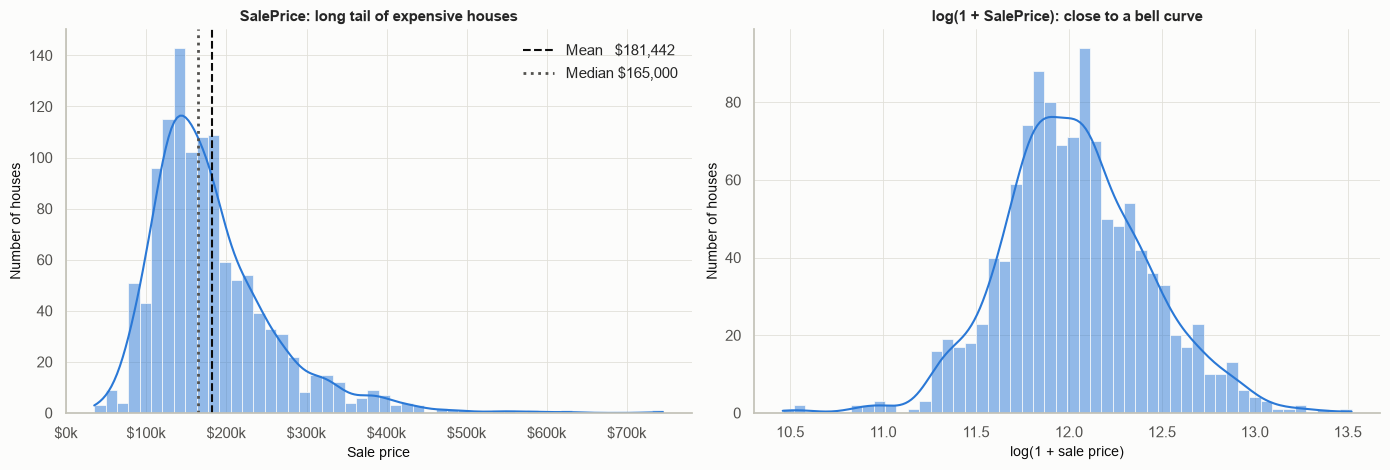

In [13]:
print(y_train.describe().map("{:,.0f}".format).to_string())
print(f"\nSkewness:                       {y_train.skew():.2f}   (0 = symmetric, > 1 = strongly right-skewed)")
print(f"Skewness after log transform:   {np.log1p(y_train).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.histplot(y_train, bins=50, kde=True, color=BLUE, edgecolor=SURFACE, linewidth=0.5, ax=axes[0])
axes[0].axvline(y_train.mean(), color=INK, linestyle="--", linewidth=1.5, label=f"Mean   ${y_train.mean():,.0f}")
axes[0].axvline(y_train.median(), color=MUTED, linestyle=":", linewidth=2, label=f"Median ${y_train.median():,.0f}")
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set(title="SalePrice: long tail of expensive houses", xlabel="Sale price", ylabel="Number of houses")
axes[0].legend(frameon=False)

sns.histplot(np.log1p(y_train), bins=50, kde=True, color=BLUE, edgecolor=SURFACE, linewidth=0.5, ax=axes[1])
axes[1].set(title="log(1 + SalePrice): close to a bell curve", xlabel="log(1 + sale price)", ylabel="Number of houses")

fig.tight_layout()
save_figure(fig, "price_distribution.png")
plt.show()

**What we see**
* Prices are **right-skewed**: most houses sell between roughly \$130k and \$215k, and a thin tail reaches
  \$700k+. The mean is pulled above the median by those expensive houses.
* After a **log transform** the distribution is roughly symmetric. We will train models on `log(price)`
  (Section 4.4). Errors then behave like *percentages*: being \$20k off on a \$100k house is treated as worse
  than \$20k off on a \$500k house, which matches how people judge price estimates.

### 3.2 Numerical features

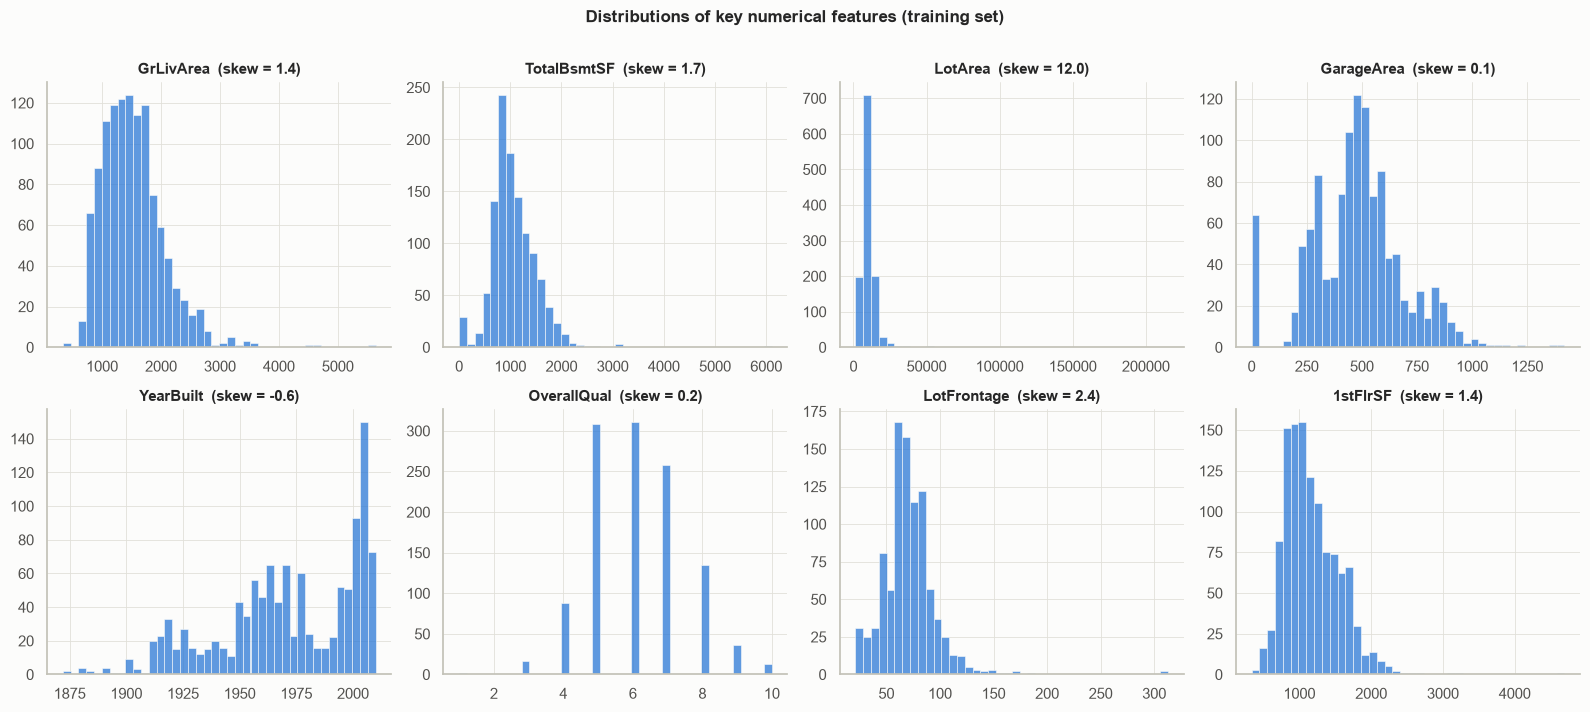

In [14]:
key_numeric = ["GrLivArea", "TotalBsmtSF", "LotArea", "GarageArea",
               "YearBuilt", "OverallQual", "LotFrontage", "1stFlrSF"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), key_numeric):
    sns.histplot(train_df[col].dropna(), bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.4, ax=ax)
    ax.set(title=f"{col}  (skew = {train_df[col].skew():.1f})", xlabel="", ylabel="")
fig.suptitle("Distributions of key numerical features (training set)", fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

In [15]:
# The most skewed numerical columns: candidates for a log transform in the linear model
train_df[numeric_columns].skew().sort_values(ascending=False).head(10).round(2).to_frame("skewness")

,skewness
MiscVal,22.05
PoolArea,14.40
LotArea,11.96
3SsnPorch,9.83
LowQualFinSF,9.20
KitchenAbvGr,4.45
BsmtFinSF2,4.22
ScreenPorch,4.09
BsmtHalfBath,4.01
EnclosedPorch,3.16


**What we see**
* Area features (`GrLivArea`, `LotArea`, `TotalBsmtSF`) are right-skewed, like the price. `LotArea` is extreme:
  a handful of huge plots stretch the scale.
* Many columns are mostly zeros (e.g. `PoolArea`, `3SsnPorch`, `MiscVal`) because most houses lack that feature.
* Skewness hurts **linear regression** (a few extreme values pull the fitted line) but does not matter to
  **tree-based models**, which only care about the *order* of values. So we will log-transform skewed columns
  for the linear model only.

### 3.3 Categorical features

In [16]:
cardinality = train_df[text_columns].nunique().sort_values(ascending=False)
category_counts = {col: train_df[col].value_counts() for col in text_columns}
total_categories = sum(len(counts) for counts in category_counts.values())
rare_categories = sum((counts < 10).sum() for counts in category_counts.values())

print("Categorical columns with the most distinct values:")
print(cardinality.head(6).to_string())
print(f"\n{rare_categories} of {total_categories} categories appear in fewer than 10 training houses.")
print("Example: Neighborhood value counts (smallest 5):")
print(category_counts["Neighborhood"].tail(5).to_string())

Categorical columns with the most distinct values:
Neighborhood    25
Exterior2nd     16
Exterior1st     15
Condition1       9
SaleType         9
HouseStyle       8

76 of 250 categories appear in fewer than 10 training houses.
Example: Neighborhood value counts (smallest 5):
Neighborhood
BrDale     13
MeadowV    10
Veenker     9
NPkVill     7
Blueste     1


Many categories are **rare**. A model cannot learn a reliable price effect from 2 or 3 houses, and a linear model
in particular may assign them extreme coefficients. We will group rare categories together (Section 4.5).

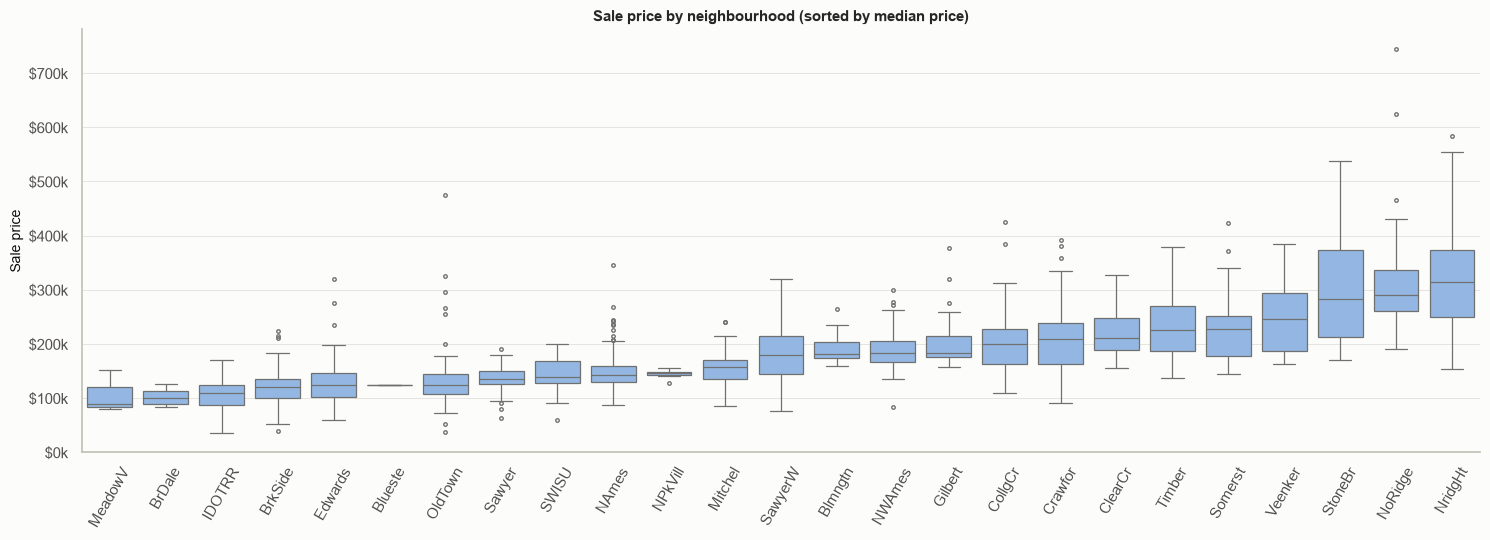

In [17]:
neighborhood_order = train_df.groupby("Neighborhood")[TARGET].median().sort_values().index

fig, ax = plt.subplots(figsize=(15, 5.5))
sns.boxplot(data=train_df, x="Neighborhood", y=TARGET, order=neighborhood_order, color=LIGHT_BLUE,
            linewidth=0.9, fliersize=2.5, ax=ax)
ax.yaxis.set_major_formatter(dollars)
ax.set(title="Sale price by neighbourhood (sorted by median price)", xlabel="", ylabel="Sale price")
ax.tick_params(axis="x", rotation=60)
fig.tight_layout()
plt.show()

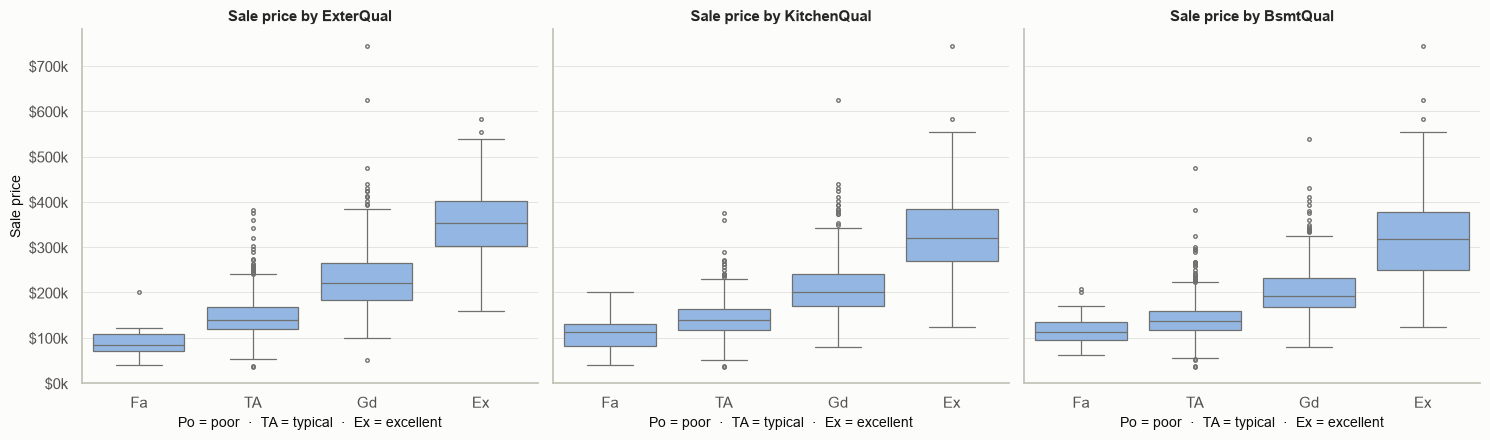

In [18]:
quality_order = ["Po", "Fa", "TA", "Gd", "Ex"]   # Poor, Fair, Typical/Average, Good, Excellent

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, col in zip(axes, ["ExterQual", "KitchenQual", "BsmtQual"]):
    order = [q for q in quality_order if q in set(train_df[col].dropna())]
    sns.boxplot(data=train_df, x=col, y=TARGET, order=order, color=LIGHT_BLUE, linewidth=0.9, fliersize=2.5, ax=ax)
    ax.set(title=f"Sale price by {col}", xlabel="Po = poor  ·  TA = typical  ·  Ex = excellent", ylabel="")
axes[0].set_ylabel("Sale price")
axes[0].yaxis.set_major_formatter(dollars)
fig.tight_layout()
plt.show()

**What we see**
* **Location matters.** The median price in the most expensive neighbourhoods (`NoRidge`, `NridgHt`, `StoneBr`)
  is roughly 2.5–3.5× that of the cheapest (`MeadowV`, `BrDale`, `IDOTRR`).
* **Quality ratings separate prices very cleanly**: each step from *Typical* → *Good* → *Excellent* raises the
  typical price substantially. These ordered categories will be strong predictors.

### 3.4 Correlation heatmap
**Correlation** (Pearson's *r*) measures how strongly two numeric columns move together in a *straight line*:
+1 = perfectly together, 0 = no linear relationship, −1 = perfectly opposite.
We show the 12 numeric features most correlated with `SalePrice`.

Saved figure -> images/correlation_heatmap.png


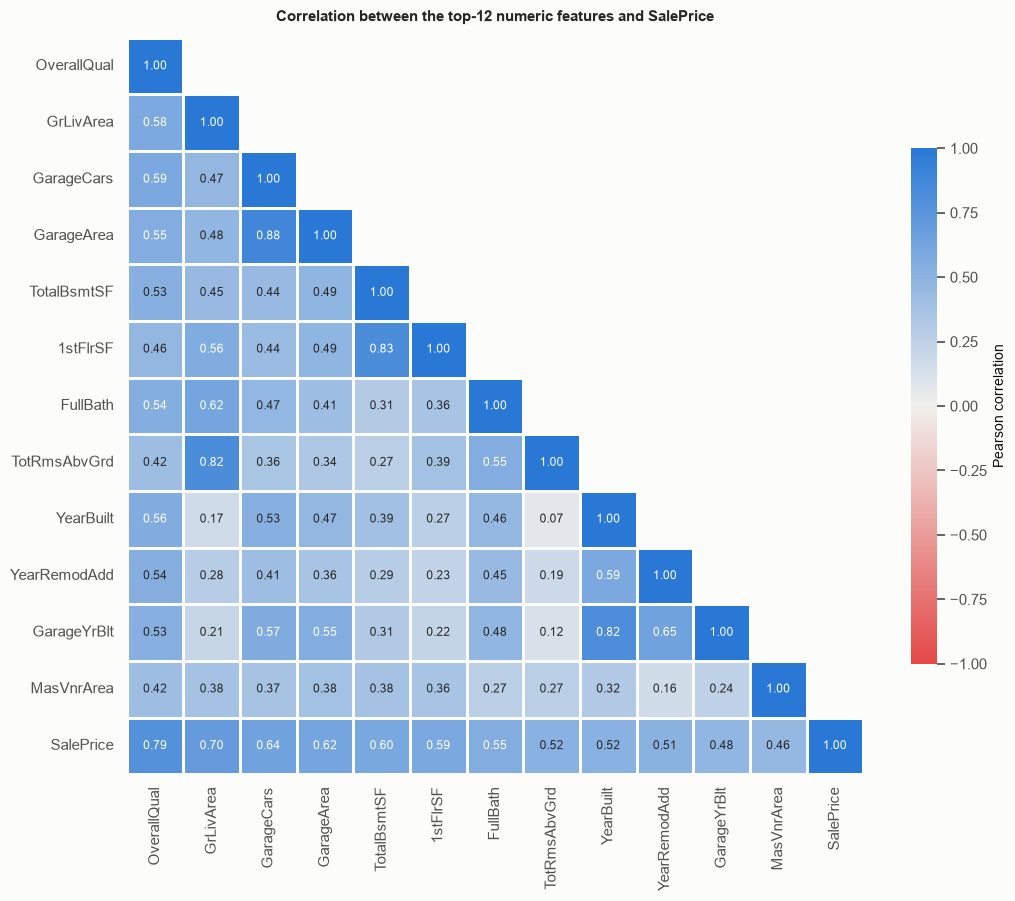

,correlation with SalePrice
OverallQual,0.786
GrLivArea,0.696
GarageCars,0.641
GarageArea,0.624
TotalBsmtSF,0.598
1stFlrSF,0.588
FullBath,0.553
TotRmsAbvGrd,0.520
YearBuilt,0.517
YearRemodAdd,0.509


In [19]:
correlations = train_df[list(numeric_columns) + [TARGET]].corr()
corr_with_price = correlations[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
top_features = corr_with_price.head(12).index.tolist()

heatmap_data = train_df[top_features + [TARGET]].corr()
upper_triangle = np.triu(np.ones_like(heatmap_data, dtype=bool), k=1)   # hide the mirrored half

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(heatmap_data, mask=upper_triangle, cmap=DIVERGING_CMAP, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8.5}, linewidths=2, linecolor=SURFACE, square=True,
            cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation between the top-12 numeric features and SalePrice", pad=12)
fig.tight_layout()
save_figure(fig, "correlation_heatmap.png")
plt.show()

corr_with_price.head(10).round(3).to_frame("correlation with SalePrice")

**What we see**
* `OverallQual` (≈ 0.8) and `GrLivArea` (≈ 0.7) have the strongest linear relationship with price,
  followed by garage size, basement area and age (`YearBuilt`).
* Some features are strongly correlated **with each other** (*multicollinearity*): `GarageCars` ↔ `GarageArea`
  (a bigger garage holds more cars), `TotalBsmtSF` ↔ `1stFlrSF`, `GrLivArea` ↔ `TotRmsAbvGrd`. They carry
  overlapping information. That is harmless for prediction with trees, but it makes individual
  linear-regression coefficients unstable and hard to interpret.

### 3.5 Relationships between important features and price

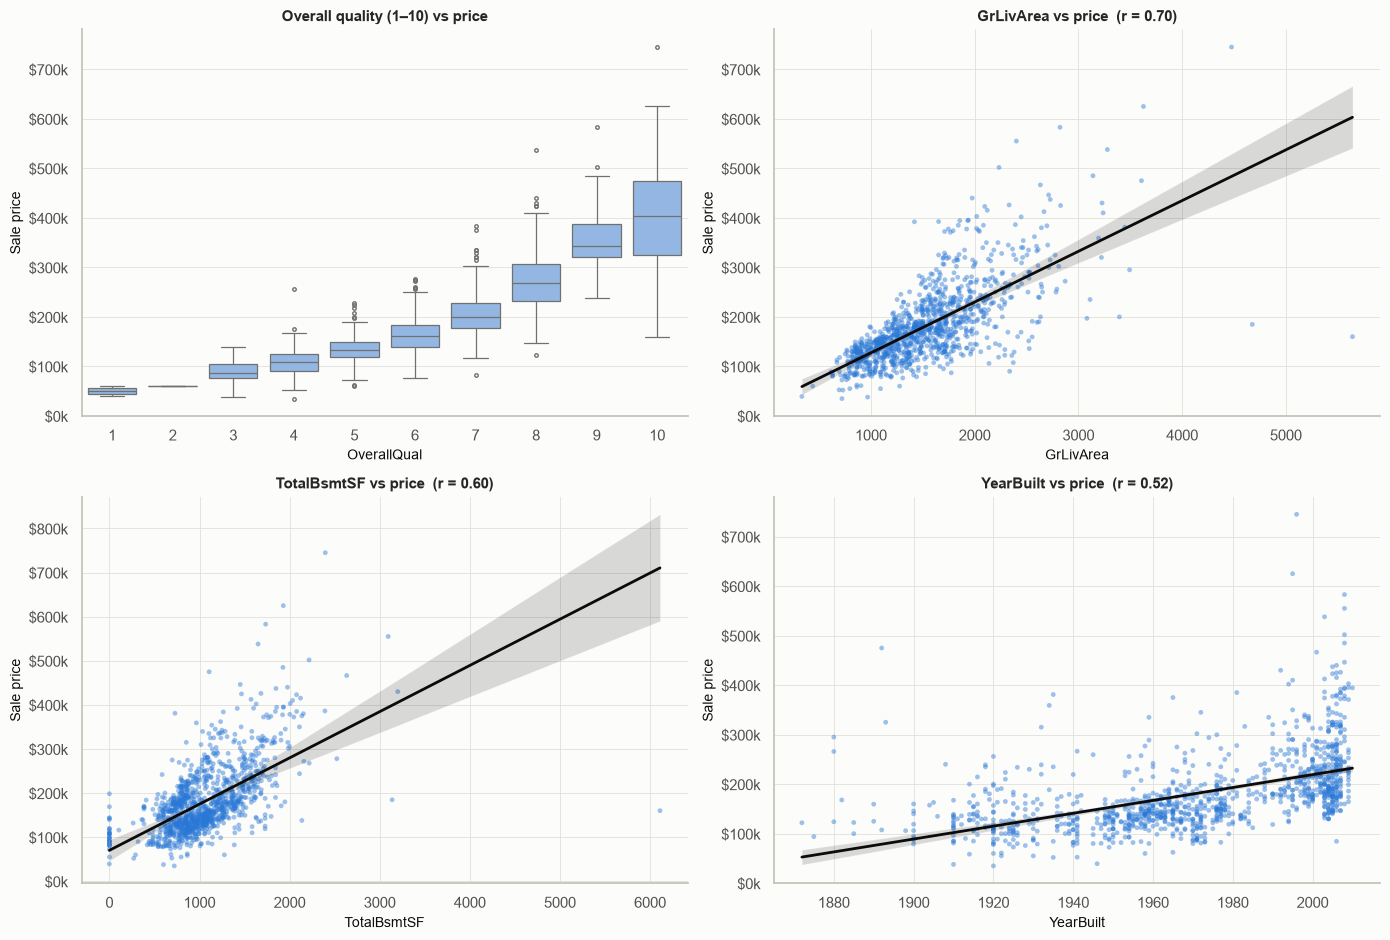

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

sns.boxplot(data=train_df, x="OverallQual", y=TARGET, color=LIGHT_BLUE, linewidth=0.9, fliersize=2.5, ax=axes[0, 0])
axes[0, 0].set(title="Overall quality (1–10) vs price", xlabel="OverallQual", ylabel="Sale price")

for ax, col in zip([axes[0, 1], axes[1, 0], axes[1, 1]], ["GrLivArea", "TotalBsmtSF", "YearBuilt"]):
    sns.regplot(data=train_df, x=col, y=TARGET, ax=ax,
                scatter_kws={"s": 12, "alpha": 0.45, "color": BLUE, "edgecolor": "none"},
                line_kws={"color": INK, "linewidth": 2})
    ax.set(title=f"{col} vs price  (r = {train_df[col].corr(train_df[TARGET]):.2f})", ylabel="Sale price")

for ax in axes.ravel():
    ax.yaxis.set_major_formatter(dollars)
fig.tight_layout()
plt.show()

**What we see**
* Price rises **faster than linearly** with `OverallQual`: the jump from 8 → 10 is much bigger than from 3 → 5.
  This curvature is another reason to model `log(price)`.
* Larger houses and newer houses sell for more, with considerable spread.
* In the `GrLivArea` plot, a couple of very large houses sit far **below** the trend line. We look at them next.

### 3.6 Potential outliers
An **outlier** is an observation that does not follow the pattern of the rest. There are two very different kinds:

1. **Genuine but unusual** values, e.g. a real \$700k luxury home. These are informative and should be **kept**.
2. **Errors or non-representative records**. These teach the model something false and may be **removed**.

The dataset's author documents exactly such a case: a few houses above 4,000 sq ft that were *partial sales*
(sold before completion) at prices far below their market value.

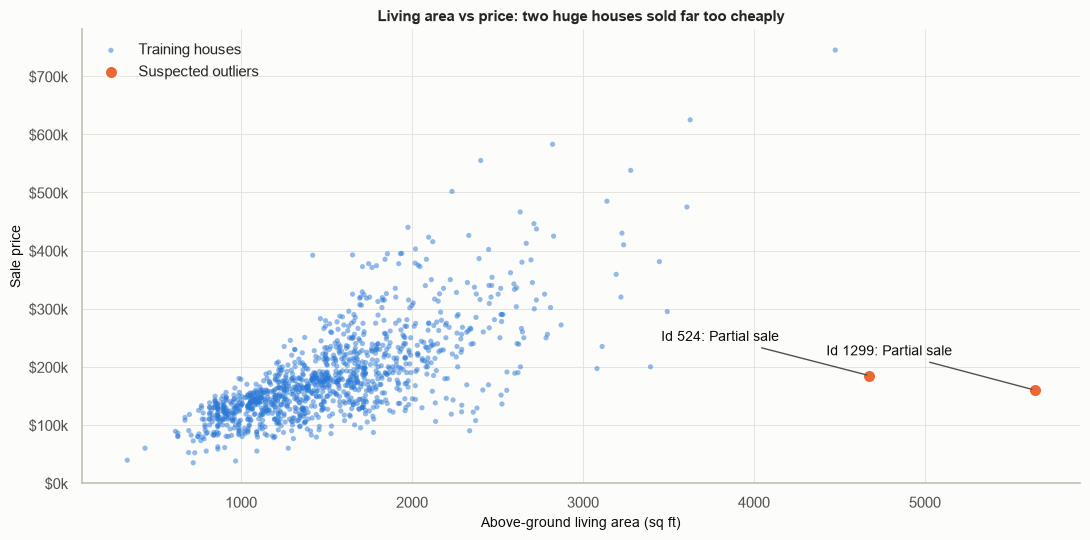

,GrLivArea,OverallQual,SaleCondition,SalePrice
Id,,,,
1183,4476,10,Abnorml,745000
524,4676,10,Partial,184750
1299,5642,10,Partial,160000


In [21]:
is_outlier = (train_df["GrLivArea"] > 4000) & (train_df[TARGET] < 300_000)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(train_df.loc[~is_outlier, "GrLivArea"], train_df.loc[~is_outlier, TARGET],
           s=14, alpha=0.5, color=BLUE, edgecolor="none", label="Training houses")
ax.scatter(train_df.loc[is_outlier, "GrLivArea"], train_df.loc[is_outlier, TARGET],
           s=90, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, label="Suspected outliers")
for house_id, row in train_df[is_outlier].iterrows():
    ax.annotate(f"Id {house_id}: {row['SaleCondition']} sale", (row["GrLivArea"], row[TARGET]),
                xytext=(-150, 25), textcoords="offset points", color=INK,
                arrowprops={"arrowstyle": "-", "color": MUTED})
ax.yaxis.set_major_formatter(dollars)
ax.set(title="Living area vs price: two huge houses sold far too cheaply",
       xlabel="Above-ground living area (sq ft)", ylabel="Sale price")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

train_df.loc[train_df["GrLivArea"] > 4000, ["GrLivArea", "OverallQual", "SaleCondition", TARGET]]

In [22]:
# For comparison: a purely statistical rule (the 1.5 x IQR "box-plot" rule) applied to the price
q1, q3 = y_train.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print(f"{(y_train > upper_fence).sum()} training houses are priced above the IQR fence of ${upper_fence:,.0f}.")

48 training houses are priced above the IQR fence of $342,312.


**Decision**
* The two orange houses are huge, top-quality (`OverallQual` = 10) homes that sold for a fraction of their value
  in **partial** sales. They contradict the strong size → price relationship, so we **remove them from the
  training set** (Section 4.1).
* The large house that sold at a high price is genuine and is **kept**.
* The IQR rule flags dozens of expensive houses. Those are **real** sales, not errors: "statistically unusual"
  does not mean "wrong", so we keep them all.
* We **never remove rows from the validation set**. It must reflect the real world, unusual houses included.

### 3.7 Missing values

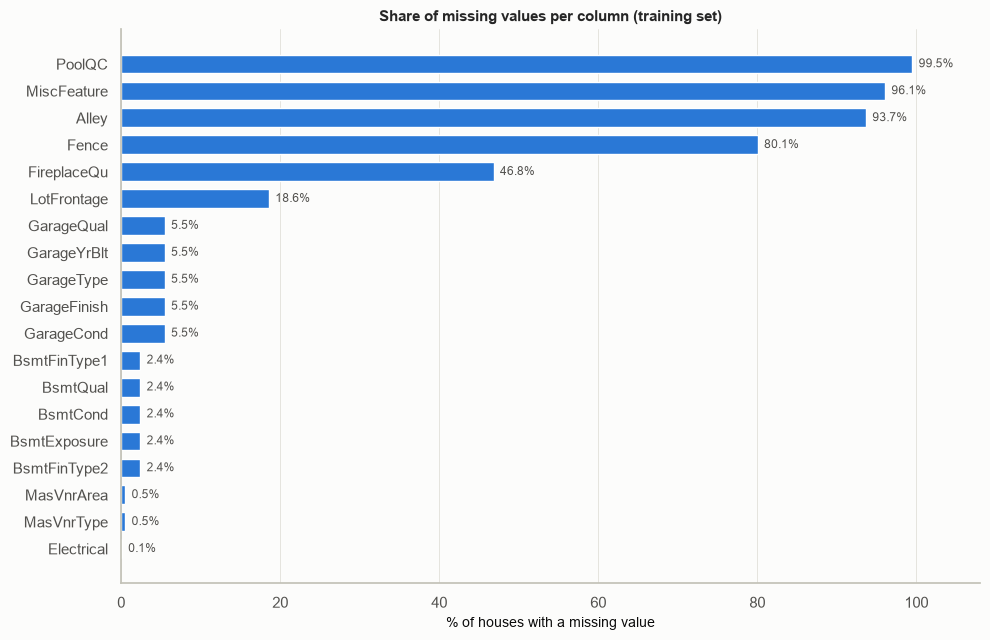

In [23]:
missing_pct = (train_df.isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(missing_pct.index[::-1], missing_pct.values[::-1], color=BLUE, height=0.7)
for i, value in enumerate(missing_pct.values[::-1]):
    ax.text(value + 0.8, i, f"{value:.1f}%", va="center", fontsize=8.5, color=MUTED)
ax.set(title="Share of missing values per column (training set)", xlabel="% of houses with a missing value")
ax.set_xlim(0, 108)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**What we see.** 19 columns have missing values, but **most of them are not really "unknown"**.
The data description says that for `PoolQC`, `Alley`, `Fence`, `FireplaceQu`, the `Garage…` and `Bsmt…` columns,
an empty value means **"this house does not have one"**: no pool, no alley access, no garage, no basement. Only a few
columns, such as `LotFrontage` (street length touching the lot), are genuinely unknown. Section 4.2 handles the two cases differently.

### 3.8 EDA summary
| Finding | Consequence for modelling |
|---|---|
| `SalePrice` is right-skewed | Train on `log(price)` |
| Area features are skewed | Log-transform them for the linear model |
| Quality, size, location and age drive price | Expect them to dominate feature importance |
| Many rare categories | Group rare categories when one-hot encoding |
| Two partial-sale outliers | Remove them from the training set only |
| Most "missing" values mean "absent" | Fill them with `"None"` / 0 instead of guessing |

---
## 4. Data Preprocessing

**The golden rule of preprocessing:** anything that *learns from data* (a median, a mean, a list of categories)
must be learned from the **training data only** and then *applied* to validation or new data.

We split preprocessing into two kinds of steps:

| Kind | Example | Where it lives |
|---|---|---|
| **Fixed rules** that learn nothing from the data | "missing `PoolQC` means no pool" → `"None"` | plain Python function `clean_data()` |
| **Learned steps** that compute statistics from the data | fill `LotFrontage` with the *median*, scale with *mean/std*, list the categories for one-hot encoding | scikit-learn `Pipeline` + `ColumnTransformer` |

Fixed rules give the same result no matter which rows they see, so they cannot leak information.
Learned steps go inside a `Pipeline`, which guarantees they are fitted only on whichever rows the model is
trained on. That holds even inside every fold of cross-validation, where doing it by hand is easy to get wrong.

### 4.1 Remove the documented outliers (training set only)

In [24]:
outlier_mask = (X_train["GrLivArea"] > 4000) & (y_train < 300_000)
print("Removing from the training set:", X_train.index[outlier_mask].tolist())

X_train = X_train.loc[~outlier_mask]
y_train = y_train.loc[~outlier_mask]
print(f"Training set now has {len(X_train):,} houses (validation set unchanged: {len(X_val)} houses).")

Removing from the training set: [524, 1299]
Training set now has 1,166 houses (validation set unchanged: 292 houses).


### 4.2 Handle missing values

| Situation | Columns | Treatment | Learns from data? |
|---|---|---|---|
| Missing = the house **does not have** the feature | `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `Garage…`, `Bsmt…`, `MasVnrType` | new category `"None"` | No → `clean_data()` |
| Missing = **zero** area | `MasVnrArea` (no masonry veneer) | `0` | No → `clean_data()` |
| Genuinely unknown **category** | `Electrical` (1 house) | its own category `"Missing"` | No → `clean_data()` |
| Genuinely unknown **number** | `LotFrontage`, `GarageYrBlt` | **median of the training rows** | **Yes → inside the Pipeline** |

*Why the median and not the mean?* `LotFrontage` is skewed, and the median is not dragged around by a few huge lots.
*Why a separate `"None"` category instead of the most common value?* "No garage" is real, useful information.
Pretending the house has a typical garage would hide it.

`clean_data()` also converts `MSSubClass` from a number to a category (see Section 2.3).

In [25]:
# Columns where a missing value means "this house does not have the feature" (from data_description.txt)
NONE_IF_MISSING = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType",
]


def clean_data(df):
    """Apply fixed, domain-based cleaning rules. Learns nothing from the data, so it cannot leak."""
    df = df.copy()
    df[NONE_IF_MISSING] = df[NONE_IF_MISSING].fillna("None")   # feature absent -> "None"
    df["MasVnrArea"] = df["MasVnrArea"].fillna(0)               # no veneer -> 0 sq ft
    df["MSSubClass"] = df["MSSubClass"].astype(str)             # dwelling-type code, not a quantity

    text_cols = df.select_dtypes(exclude="number").columns
    df[text_cols] = df[text_cols].fillna("Missing")             # any other unknown category
    return df


before = X_train.isna().sum()
after = clean_data(X_train).isna().sum()
missing_summary = pd.DataFrame({"missing before": before, "missing after clean_data()": after})
missing_summary[missing_summary["missing before"] > 0].sort_values("missing before", ascending=False)

,missing before,missing after clean_data()
PoolQC,1161,0
MiscFeature,1120,0
Alley,1092,0
Fence,933,0
FireplaceQu,547,0
LotFrontage,217,217
GarageCond,64,0
GarageType,64,0
GarageYrBlt,64,64
GarageFinish,64,0


Only the genuinely unknown numeric values (`LotFrontage`, `GarageYrBlt`) remain. The pipelines in Section 6 fill
them with the training median. CatBoost can also handle missing numbers natively, so it receives them as they are.

### 4.3 Separate numerical and categorical features
Models need numbers. The two feature types are prepared differently:

* **Numerical** (areas, counts, years, ratings): impute missing values, and for the linear model, transform and scale.
* **Categorical** (neighbourhood, quality labels, …): turn text into numbers (encoding).

We find the column lists automatically from the data types, *after* feature engineering (Section 6.1),
so the new features are included.

### 4.4 Transform the target: train on `log(price)`
From the EDA we know the price is right-skewed. Training on `log(1 + price)` has three benefits:

1. Errors become **relative**: a 10% error costs the same for a cheap and an expensive house.
2. The relationship between features and price becomes **more linear** (helps Linear Regression a lot).
3. A few very expensive houses no longer dominate the training objective.

scikit-learn's **`TransformedTargetRegressor`** applies `np.log1p` to the target before training and the inverse,
`np.expm1`, to predictions. So we train in log space but **every prediction and every metric is in dollars**.

In [26]:
# log1p turns equal *ratios* into equal *steps*: each doubling of the price adds the same amount (~0.69)
example_prices = np.array([100_000, 200_000, 400_000, 800_000])
pd.DataFrame({"price": example_prices, "log1p(price)": np.log1p(example_prices).round(3),
              "back with expm1": np.expm1(np.log1p(example_prices)).round(0)})

,price,log1p(price),back with expm1
0,100000,11.513,100000.0
1,200000,12.206,200000.0
2,400000,12.899,400000.0
3,800000,13.592,800000.0


### 4.5 Encode categoricals, transform and scale numerics

Each model family needs different preparation, so each gets **its own preprocessing pipeline**:

| Step | Linear Regression | Random Forest | CatBoost |
|---|---|---|---|
| Missing numbers | median imputation | median imputation | handled natively |
| Skewed numbers | `log1p` transform | not needed (trees use only the *order* of values) | not needed |
| Scaling | `StandardScaler` (mean 0, std 1) | not needed | not needed |
| Categories | one-hot encoding, rare categories grouped | one-hot encoding, rare categories grouped | **native** categorical support |

**One-hot encoding** turns a column like `CentralAir ∈ {Y, N}` into indicator columns `CentralAir_Y`, `CentralAir_N`
holding 0/1. With `min_frequency=10`, categories seen in fewer than 10 training houses are merged into a single
*"infrequent"* column. `handle_unknown="infrequent_if_exist"` maps categories that never appeared in training
(possible for new houses) into that same bucket instead of crashing.

**Why scale for linear regression?** Here scaling doesn't change the predictions of plain least squares. It
puts all coefficients on a comparable scale and keeps the computation numerically well-behaved. Trees ignore it.

**Why log-transform skewed features?** A linear model fits straight lines. `log(area)` vs `log(price)` is much
closer to a straight line than `area` vs `price`, and extreme values stop dominating the fit.

In [27]:
def make_one_hot_encoder():
    """One-hot encode categories; group categories seen in < 10 training houses (and unseen ones)."""
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)


def make_linear_preprocessor(skewed_cols, other_numeric_cols, categorical_cols):
    """Preprocessing for Linear Regression: impute -> log (skewed only) -> scale; one-hot for categories."""
    skewed_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),                               # median learned on training rows
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),     # compress long right tails
        ("scale", StandardScaler()),                                                # mean 0, standard deviation 1
    ])
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("skewed_numeric", skewed_pipeline, skewed_cols),
        ("numeric", numeric_pipeline, other_numeric_cols),
        ("categorical", make_one_hot_encoder(), categorical_cols),
    ])


def make_tree_preprocessor(numeric_cols, categorical_cols):
    """Preprocessing for Random Forest: impute numbers; one-hot for categories. No scaling needed."""
    return ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric_cols),
        ("categorical", make_one_hot_encoder(), categorical_cols),
    ])

---
## 5. Feature Engineering

**Feature engineering** means creating new input columns from existing ones, using domain knowledge.
A good feature states directly something the model would otherwise have to work out on its own.

| New feature | Formula | Why it may help |
|---|---|---|
| `TotalSF` | basement + 1st floor + 2nd floor area | Buyers pay for **total usable space**. Size is spread over three columns; their sum is a single, stronger signal. |
| `HouseAge` | `YrSold − YearBuilt` | What matters is how old the house was **when it was sold**, not the calendar year it was built. |
| `YearsSinceRemodel` | `YrSold − YearRemodAdd` | A recently renovated old house can be worth as much as a newer one. |
| `TotalBathrooms` | full + ½·half baths (above ground and basement) | Bathrooms are split over four columns; a half bath counts as half. |
| `TotalPorchSF` | open + enclosed + 3-season + screen porch areas | Five sparse, mostly-zero columns → one meaningful "outdoor living space" number. |

All five are **fixed formulas**: they learn nothing from the data, so it is safe to apply them to any dataset.
We use the **same function** for training, validation and future predictions. Using different code at
prediction time than at training time ("training/serving skew") is a common source of bugs in real ML systems.

In [28]:
def add_features(df):
    """Create domain-knowledge features. Pure formulas: no statistics are learned from the data."""
    df = df.copy()
    df["TotalSF"] = df["TotalBsmtSF"].fillna(0) + df["1stFlrSF"] + df["2ndFlrSF"]
    df["HouseAge"] = (df["YrSold"] - df["YearBuilt"]).clip(lower=0)
    df["YearsSinceRemodel"] = (df["YrSold"] - df["YearRemodAdd"]).clip(lower=0)
    df["TotalBathrooms"] = (df["FullBath"] + 0.5 * df["HalfBath"]
                            + df["BsmtFullBath"].fillna(0) + 0.5 * df["BsmtHalfBath"].fillna(0))
    df["TotalPorchSF"] = df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"]
    return df


def prepare_features(df):
    """Full fixed-rule preparation: cleaning + feature engineering. Used for training AND prediction."""
    return add_features(clean_data(df))


X_train_prepared = prepare_features(X_train)
X_val_prepared = prepare_features(X_val)
print(f"Features before: {X_train.shape[1]}   after feature engineering: {X_train_prepared.shape[1]}")
X_train_prepared[["TotalSF", "HouseAge", "YearsSinceRemodel", "TotalBathrooms", "TotalPorchSF"]].describe().round(1)

Features before: 79   after feature engineering: 84


,TotalSF,HouseAge,YearsSinceRemodel,TotalBathrooms,TotalPorchSF
count,1166.0,1166.0,1166.0,1166.0,1166.0
mean,2571.1,36.9,23.0,2.2,90.2
std,761.5,30.7,20.7,0.8,107.7
min,334.0,0.0,0.0,1.0,0.0
25%,2029.5,7.0,4.0,2.0,0.0
50%,2491.5,35.0,14.0,2.0,51.0
75%,3009.5,55.0,42.0,2.5,140.0
max,6872.0,136.0,60.0,6.0,1027.0


Do the new features carry more signal than their ingredients? We compare their correlation with the
(log) price, on the training set.

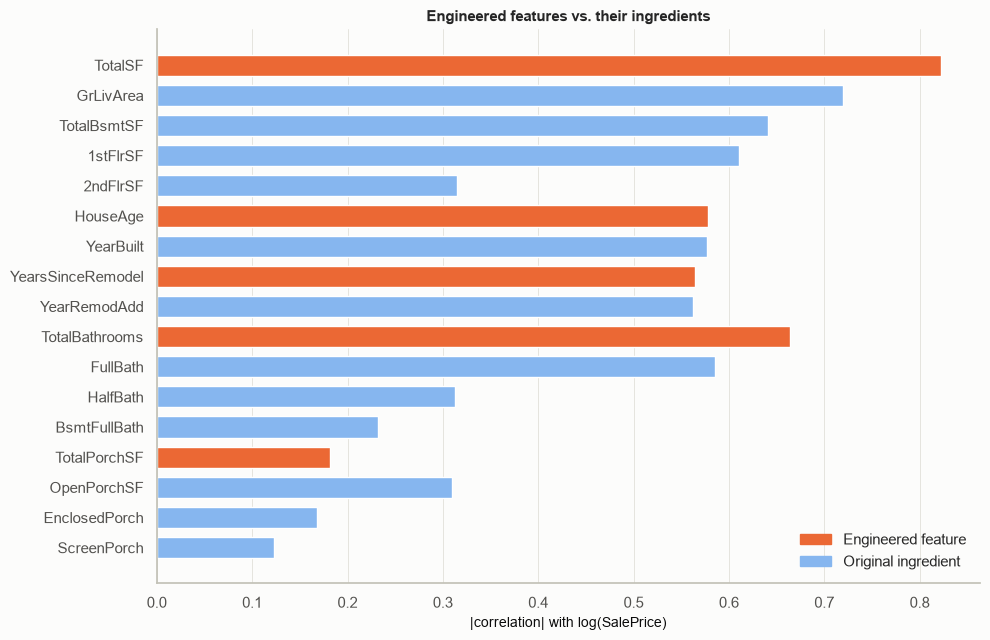

In [29]:
log_price_train = np.log1p(y_train)
feature_groups = {
    "TotalSF": ["GrLivArea", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF"],
    "HouseAge": ["YearBuilt"],
    "YearsSinceRemodel": ["YearRemodAdd"],
    "TotalBathrooms": ["FullBath", "HalfBath", "BsmtFullBath"],
    "TotalPorchSF": ["OpenPorchSF", "EnclosedPorch", "ScreenPorch"],
}

rows = []
for new_feature, ingredients in feature_groups.items():
    for col in [new_feature] + ingredients:
        rows.append({"group": new_feature, "feature": col, "engineered": col == new_feature,
                     "abs_corr": abs(X_train_prepared[col].corr(log_price_train))})
feature_corr = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 6.5))
labels = [f"{r.feature}" for r in feature_corr.itertuples()][::-1]
colors = [ORANGE if r.engineered else LIGHT_BLUE for r in feature_corr.itertuples()][::-1]
ax.barh(labels, feature_corr["abs_corr"][::-1], color=colors, height=0.7)
ax.set(title="Engineered features vs. their ingredients", xlabel="|correlation| with log(SalePrice)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=ORANGE, label="Engineered feature"), Patch(color=LIGHT_BLUE, label="Original ingredient")],
          frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

* `TotalSF` and `TotalBathrooms` are **more strongly related to price than any of their ingredients**. Combining
  scattered information into one number paid off.
* `HouseAge` and `YearsSinceRemodel` carry the same information as `YearBuilt` / `YearRemodAdd`, in more natural units.
* `TotalPorchSF` is **weaker** than `OpenPorchSF` alone: the porch types relate to price differently, and summing them
  blurs the signal. **Not every engineered feature helps.** That is normal, and tree models can simply ignore a weak feature.

Correlation only measures *linear*, one-at-a-time relationships. The real test is whether the models use these
features, which we will see in Section 9.

---
## 6. Model Training

### 6.1 Final column groups

In [30]:
categorical_cols = X_train_prepared.select_dtypes(exclude="number").columns.tolist()
numeric_cols = X_train_prepared.select_dtypes(include="number").columns.tolist()

# Skewed, non-negative numeric columns get a log transform in the linear model.
# The list is decided from the TRAINING set only.
skewness = X_train_prepared[numeric_cols].skew()
skewed_cols = [col for col in numeric_cols if skewness[col] > 0.75 and X_train_prepared[col].min() >= 0]
other_numeric_cols = [col for col in numeric_cols if col not in skewed_cols]

print(f"Categorical columns:   {len(categorical_cols)}")
print(f"Numeric columns:       {len(numeric_cols)}  ({len(skewed_cols)} of them skewed -> log1p for the linear model)")
print("Skewed:", ", ".join(skewed_cols))

Categorical columns:   44
Numeric columns:       40  (20 of them skewed -> log1p for the linear model)
Skewed: LotFrontage, LotArea, MasVnrArea, BsmtFinSF2, BsmtUnfSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtHalfBath, KitchenAbvGr, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, TotalSF, TotalPorchSF


### 6.2 The three models

| Model | How it works (in one paragraph) | Strengths | Weaknesses |
|---|---|---|---|
| **Linear Regression** | Fits one weight per feature so that *price ≈ w₁·x₁ + w₂·x₂ + … + b*, minimising squared error. | Fast, transparent, extrapolates trends, strong **baseline** | Only straight-line effects; needs careful preprocessing; sensitive to outliers and correlated features |
| **Random Forest** | Trains hundreds of decision trees, each on a random sample of houses and features, and **averages** their predictions (*bagging*). | Captures non-linear effects and interactions, robust, little tuning | Cannot predict outside the range of training prices; one-hot categories dilute its splits |
| **CatBoost** | Gradient boosting: builds trees **one after another**, each new tree correcting the errors of the previous ones. Handles categorical text columns natively with *ordered target statistics*. | Usually the most accurate on tabular data; minimal preprocessing | Slower to train; more hyperparameters; less transparent (→ SHAP) |

All three are wrapped in `TransformedTargetRegressor` (train on log price, predict dollars) and use a fixed
random seed.

**CatBoost settings.** `iterations` = number of trees, `learning_rate` = how much each tree corrects the previous
ones, `depth` = tree depth. CatBoost has two ways to handle a text column itself (no preprocessing by us):
*one-hot encoding* for columns with few distinct values, and *ordered target statistics* (it replaces each category
with a carefully computed average price) for columns with many values, such as zip codes. Every categorical column
here has at most 25 distinct values, so we set `one_hot_max_size=255` and CatBoost one-hot encodes all of them
internally. In our experiments the target-statistics route was **about 30× slower** on this dataset (several minutes
per model on a laptop) and *not* more accurate.

**A note on CatBoost and scikit-learn:** we pass `cat_features` as a **tuple**, not a list. scikit-learn copies
models with `clone()` during cross-validation and checks that each setting comes back as the identical object.
CatBoost hands back a *copy* of a list, which fails that check. A tuple of strings survives the copy unchanged.

In [31]:
def log_target(regressor):
    """Wrap a model so it trains on log1p(price) but predicts in dollars."""
    return TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)


CATBOOST_PARAMS = {
    "iterations": 1000,
    "learning_rate": 0.05,
    "depth": 6,
    "one_hot_max_size": 255,       # one-hot encode every categorical column internally (all have <= 25 values)
    "cat_features": tuple(categorical_cols),   # tuple, not list: required by sklearn's clone()
    "random_seed": RANDOM_STATE,
    "verbose": 0,
    "allow_writing_files": False,  # don't create a catboost_info/ folder
    "thread_count": -1,            # use all available CPU cores
}

models = {
    "Linear Regression": log_target(Pipeline([
        ("preprocess", make_linear_preprocessor(skewed_cols, other_numeric_cols, categorical_cols)),
        ("model", LinearRegression()),
    ])),
    "Random Forest": log_target(Pipeline([
        ("preprocess", make_tree_preprocessor(numeric_cols, categorical_cols)),
        ("model", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    ])),
    "CatBoost": log_target(CatBoostRegressor(**CATBOOST_PARAMS)),
}

models["Linear Regression"]   # Jupyter draws the full pipeline as a diagram

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...egression())])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, t

### 6.3 Five-fold cross-validation on the training set

A single validation set of 292 houses is a fairly small sample: one unusual house can noticeably change the
score. **K-fold cross-validation** gives a more stable estimate:

```
Training set split into 5 folds:  [1][2][3][4][5]
Round 1: train on 2-5, score on 1
Round 2: train on 1,3,4,5, score on 2      ... 5 rounds; average the 5 scores
```

Because every model is a `Pipeline`, `cross_validate` refits the **whole pipeline** (imputer medians, scaler,
one-hot categories) inside each round, using only that round's training folds. No information leaks from the
fold being scored.

All models use **the same 5 folds**, so we can also compare them *fold by fold* (a paired comparison).

In [32]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

cv_rows = []
fold_rmse, fold_mae = {}, {}      # per-fold scores, used for paired comparisons later
for name, model in models.items():
    start = time.perf_counter()
    scores = cross_validate(model, X_train_prepared, y_train, cv=cv, scoring=scoring)
    fold_rmse[name], fold_mae[name] = -scores["test_RMSE"], -scores["test_MAE"]
    cv_rows.append({
        "Model": name,
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV RMSE std": scores["test_RMSE"].std(),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV R²": scores["test_R2"].mean(),
        "Time (s)": time.perf_counter() - start,
    })
    print(f"{name:<18} done in {cv_rows[-1]['Time (s)']:.0f}s")

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.round({"CV RMSE": 0, "CV RMSE std": 0, "CV MAE": 0, "CV R²": 4, "Time (s)": 1})

Linear Regression  done in 3s


Random Forest      done in 9s


CatBoost           done in 24s


,CV RMSE,CV RMSE std,CV MAE,CV R²,Time (s)
Model,,,,,
Linear Regression,21370.0,967.0,14332.0,0.9233,2.5
Random Forest,26071.0,1091.0,16525.0,0.8854,8.9
CatBoost,22643.0,2423.0,13510.0,0.9124,23.6


### 6.4 Train on the full training set and predict the validation set
Now each model is trained once on all 1,166 training houses and asked to price the 292 validation houses
it has never seen.

In [33]:
val_predictions = {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train_prepared, y_train)
    val_predictions[name] = model.predict(X_val_prepared)
    print(f"{name:<18} trained in {time.perf_counter() - start:5.1f}s")

n_features_linear = models["Linear Regression"].regressor_.named_steps["preprocess"].transform(X_train_prepared.head()).shape[1]
print(f"\nAfter one-hot encoding the linear model sees {n_features_linear} numeric input columns.")

Linear Regression  trained in   0.5s


Random Forest      trained in   2.1s


CatBoost           trained in   4.9s

After one-hot encoding the linear model sees 271 numeric input columns.


---
## 7. Model Evaluation

### 7.1 The metrics
With $y_i$ the true price, $\hat{y}_i$ the prediction and $n$ houses:

| Metric | Formula | Meaning | Good value |
|---|---|---|---|
| **MAE** – Mean Absolute Error | $\frac{1}{n}\sum \lvert y_i-\hat{y}_i\rvert$ | "On average we are off by \$X." Easy to explain to anyone. | lower |
| **RMSE** – Root Mean Squared Error | $\sqrt{\frac{1}{n}\sum (y_i-\hat{y}_i)^2}$ | Also in dollars, but **squares** errors first, so large mistakes count much more. RMSE ≥ MAE; a big gap means a few large errors. | lower |
| **R²** – coefficient of determination | $1-\frac{\sum (y_i-\hat{y}_i)^2}{\sum (y_i-\bar{y})^2}$ | Share of the price variation the model explains. 0 = no better than always guessing the average; 1 = perfect. | closer to 1 |
| **RMSLE** (bonus) | RMSE of $\log(1+y)$ | Kaggle's leaderboard metric; ≈ the typical *percentage* error (0.12 ≈ 12%). | lower |
| **Within 10%** (bonus) | share of houses with $\lvert\hat{y}-y\rvert/y \le 10\%$ | A business-friendly view: how often is the estimate "close enough"? | higher |

In [34]:
def regression_metrics(y_true, y_pred):
    """All evaluation metrics for one set of predictions (prices in dollars)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
        "RMSLE": np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred))),
        "Within 10%": np.mean(np.abs(y_pred - y_true) / y_true <= 0.10),
    }


val_results = pd.DataFrame({name: regression_metrics(y_val, pred) for name, pred in val_predictions.items()}).T
comparison = val_results.join(cv_results[["CV RMSE", "CV RMSE std", "CV MAE"]])
comparison.index.name = "Model"
print("Validation-set metrics (292 unseen houses) + 5-fold CV metrics (training set). Best value in bold.")

(comparison.style
    .format({"MAE": "${:,.0f}", "RMSE": "${:,.0f}", "R²": "{:.4f}", "RMSLE": "{:.4f}", "Within 10%": "{:.1%}",
             "CV RMSE": "${:,.0f}", "CV RMSE std": "±${:,.0f}", "CV MAE": "${:,.0f}"})
    .highlight_min(subset=["MAE", "RMSE", "RMSLE", "CV RMSE", "CV MAE"], props="font-weight:bold")
    .highlight_max(subset=["R²", "Within 10%"], props="font-weight:bold"))

Validation-set metrics (292 unseen houses) + 5-fold CV metrics (training set). Best value in bold.


,MAE,RMSE,R²,RMSLE,Within 10%,CV RMSE,CV RMSE std,CV MAE
Model,,,,,,,,
Linear Regression,"$14,970","$22,778",0.9324,0.1254,70.2%,"$21,370",±$967,"$14,332"
Random Forest,"$17,169","$29,089",0.8897,0.1473,68.8%,"$26,071","±$1,091","$16,525"
CatBoost,"$14,213","$24,967",0.9187,0.1243,76.7%,"$22,643","±$2,423","$13,510"


Saved figure -> images/model_comparison.png


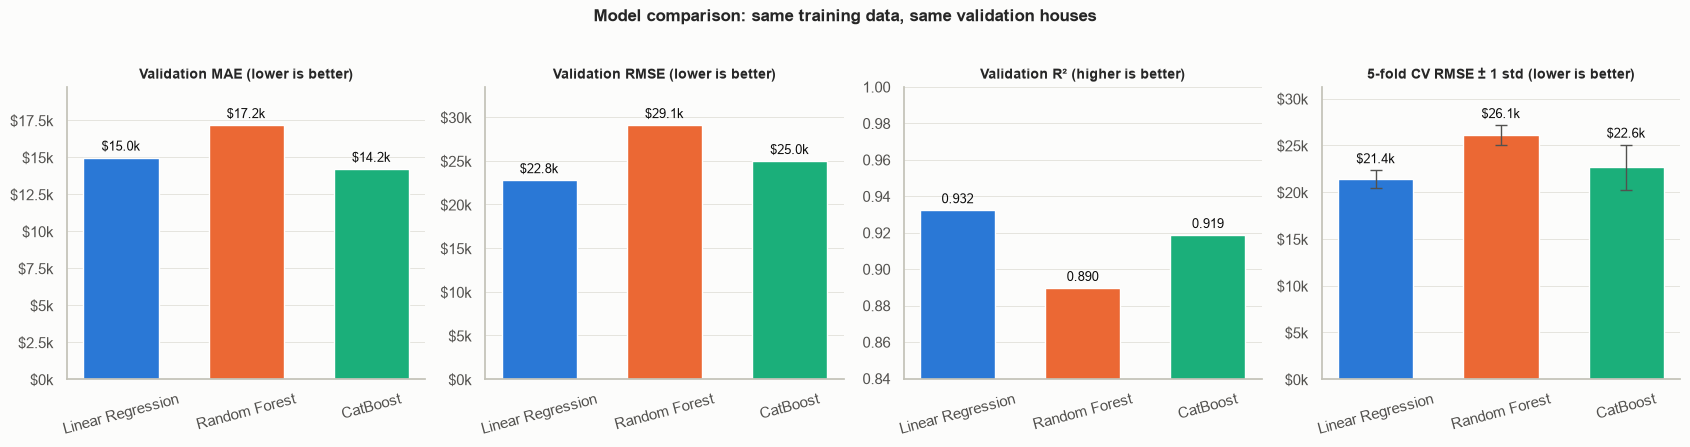

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3))
names = list(val_results.index)
colors = [MODEL_COLORS[n] for n in names]
panels = [
    ("MAE", val_results["MAE"], None, "Validation MAE (lower is better)", True),
    ("RMSE", val_results["RMSE"], None, "Validation RMSE (lower is better)", True),
    ("R²", val_results["R²"], None, "Validation R² (higher is better)", False),
    ("CV RMSE", cv_results.loc[names, "CV RMSE"], cv_results.loc[names, "CV RMSE std"],
     "5-fold CV RMSE ± 1 std (lower is better)", True),
]
for ax, (metric, values, errors, title, is_money) in zip(axes, panels):
    values = np.asarray(values)
    errors = np.zeros_like(values) if errors is None else np.asarray(errors)
    ax.bar(names, values, yerr=errors if errors.any() else None, color=colors, width=0.6, capsize=4,
           error_kw={"ecolor": MUTED, "elinewidth": 1})
    if is_money:
        ax.yaxis.set_major_formatter(dollars)
        ax.set_ylim(0, (values + errors).max() * 1.15)
    else:
        ax.set_ylim(values.min() - 0.05, 1.0)
    pad = (ax.get_ylim()[1] - ax.get_ylim()[0]) * 0.015
    for x, (value, error) in enumerate(zip(values, errors)):      # value label just above the bar / error bar
        label = f"${value / 1000:,.1f}k" if is_money else f"{value:.3f}"
        ax.text(x, value + error + pad, label, ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="x", visible=False)
fig.suptitle("Model comparison: same training data, same validation houses", fontweight="bold", y=1.03)
fig.tight_layout()
save_figure(fig, "model_comparison.png")
plt.show()

### 7.2 Actual vs. predicted prices
Each dot is one validation house. A perfect model would put every dot on the dashed diagonal.

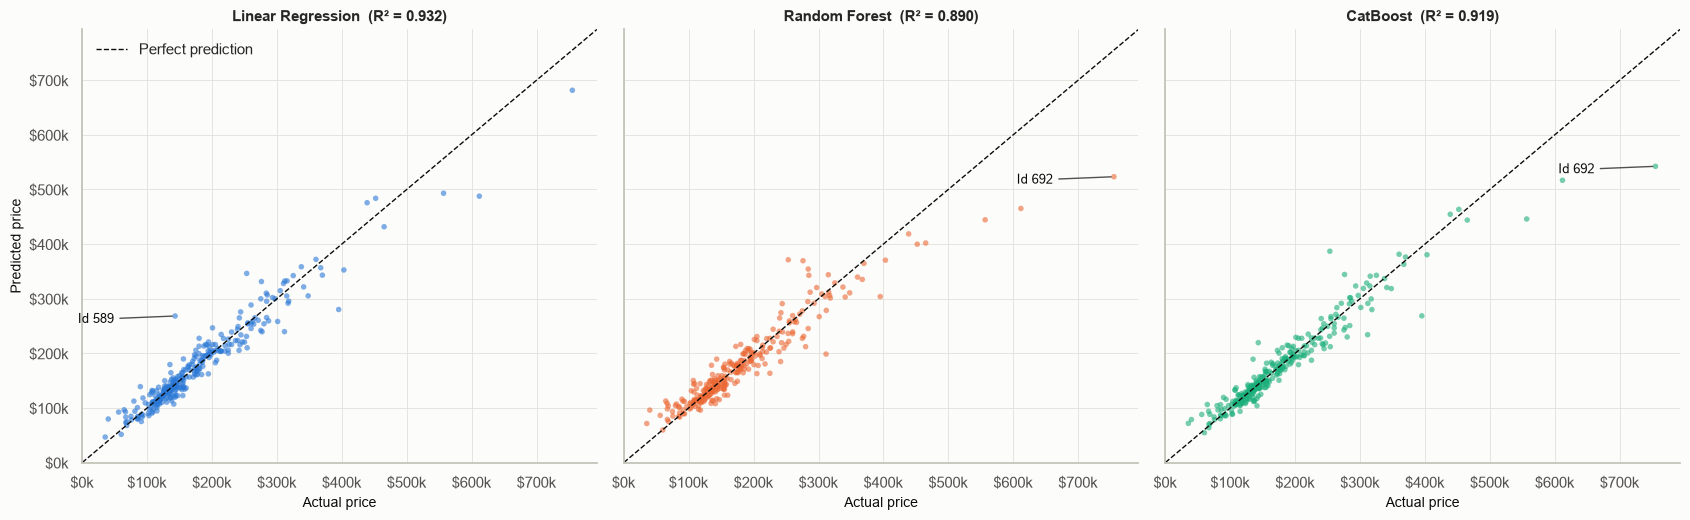

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.3), sharex=True, sharey=True)
limits = [0, max(y_val.max(), max(p.max() for p in val_predictions.values())) * 1.05]

for ax, (name, pred) in zip(axes, val_predictions.items()):
    ax.scatter(y_val, pred, s=16, alpha=0.6, color=MODEL_COLORS[name], edgecolor="none")
    ax.plot(limits, limits, linestyle="--", color=INK, linewidth=1, label="Perfect prediction")
    worst = np.argmax(np.abs(pred - y_val.values))     # label the single largest error
    ax.annotate(f"Id {y_val.index[worst]}", (y_val.iloc[worst], pred[worst]), xytext=(-70, -5),
                textcoords="offset points", fontsize=9, color=INK, arrowprops={"arrowstyle": "-", "color": MUTED})
    ax.set(title=f"{name}  (R² = {r2_score(y_val, pred):.3f})", xlabel="Actual price", xlim=limits, ylim=limits)
    ax.xaxis.set_major_formatter(dollars)
    ax.yaxis.set_major_formatter(dollars)
axes[0].set_ylabel("Predicted price")
axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

**What we see**
* For typical houses (≈ \$100k–\$350k) all three models stay close to the diagonal.
* At the top end the two **tree models flatten out**: house 692 sold for \$755k but Random Forest and CatBoost predict
  only about \$520k–\$540k. A tree predicts averages of training prices, so it **cannot predict above the most
  expensive houses it has seen**. Linear Regression extrapolates its straight-line trend and gets much closer (\$681k).

### 7.3 Residual distributions
A **residual** is *actual − predicted*. Positive = the model **under**-estimated the price; negative = it
**over**-estimated. Ideally residuals are centred on zero, symmetric and narrow.

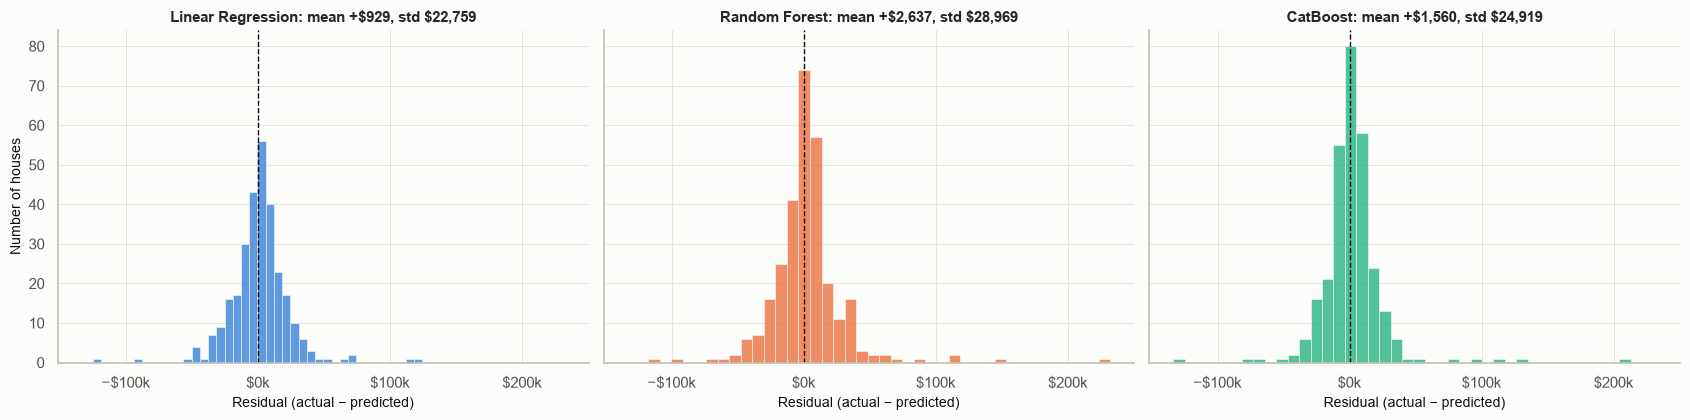

In [37]:
residuals = {name: y_val.values - pred for name, pred in val_predictions.items()}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), sharex=True, sharey=True)
for ax, (name, res) in zip(axes, residuals.items()):
    sns.histplot(res, bins=40, color=MODEL_COLORS[name], edgecolor=SURFACE, linewidth=0.4, ax=ax)
    ax.axvline(0, color=INK, linestyle="--", linewidth=1)
    # note: "\$" prints a literal dollar sign (a pair of plain "$" would switch matplotlib to math mode)
    ax.set(title=f"{name}: mean {'+' if np.mean(res) >= 0 else '−'}\\${abs(np.mean(res)):,.0f}, std \\${np.std(res):,.0f}",
           xlabel="Residual (actual − predicted)")
    ax.xaxis.set_major_locator(MultipleLocator(100_000))
    ax.xaxis.set_major_formatter(dollars)
axes[0].set_ylabel("Number of houses")
fig.tight_layout()
plt.show()

**What we see.** All three models are almost unbiased (mean residual within ±\$3k of zero) with roughly symmetric
residuals and long tails: a few houses are missed by \$100k or more. CatBoost's residuals are the most tightly
concentrated around zero (the tallest central bars), which is why it has the lowest MAE and the most houses within ±10%.

### 7.4 Residual analysis
Where exactly do the models go wrong? We look at the largest errors and at how error changes with price.

In [38]:
# Houses that are hard for *every* model: sort by the average absolute error of the three models
error_table = pd.DataFrame({"Actual price": y_val})
for name, res in residuals.items():
    error_table[f"{name} residual"] = res
residual_cols = [c for c in error_table.columns if c.endswith("residual")]
error_table["mean |residual|"] = error_table[residual_cols].abs().mean(axis=1)
error_table = error_table.join(X_val[["OverallQual", "GrLivArea", "YearBuilt", "SaleCondition"]])

print("The 5 hardest validation houses (residual = actual − predicted; positive = price was under-estimated):")
(error_table.sort_values("mean |residual|", ascending=False).head(5)
    .style.format({c: "${:,.0f}" for c in ["Actual price", "mean |residual|"] + residual_cols}))

The 5 hardest validation houses (residual = actual − predicted; positive = price was under-estimated):


,Actual price,Linear Regression residual,Random Forest residual,CatBoost residual,mean |residual|,OverallQual,GrLivArea,YearBuilt,SaleCondition
Id,,,,,,,,,
692,"$755,000","$73,556","$231,848","$212,772","$172,725",10,4316,1994,Normal
899,"$611,657","$124,108","$146,587","$95,057","$121,917",9,2364,2009,Partial
582,"$253,293","$-92,851","$-117,795","$-133,468","$114,705",8,2042,2008,Partial
775,"$395,000","$114,923","$91,236","$126,522","$110,894",8,1973,2006,Partial
1047,"$556,581","$63,636","$112,255","$110,795","$95,562",9,2868,2005,Partial


In [39]:
# How much does one house influence RMSE? Recompute each model's RMSE without the single most expensive house.
most_expensive = y_val.idxmax()
keep = y_val.index != most_expensive
influence = pd.DataFrame({
    "RMSE (all 292 houses)": {n: np.sqrt(mean_squared_error(y_val, p)) for n, p in val_predictions.items()},
    f"RMSE without house {most_expensive}": {n: np.sqrt(mean_squared_error(y_val[keep], p[keep]))
                                              for n, p in val_predictions.items()},
    f"Prediction for house {most_expensive}": {n: p[~keep][0] for n, p in val_predictions.items()},
})
print(f"House {most_expensive} actually sold for ${y_val.max():,.0f}.")
influence.style.format("${:,.0f}")

House 692 actually sold for $755,000.


,RMSE (all 292 houses),RMSE without house 692,Prediction for house 692
Linear Regression,"$22,778","$22,406","$681,444"
Random Forest,"$29,089","$25,775","$523,152"
CatBoost,"$24,967","$21,678","$542,228"


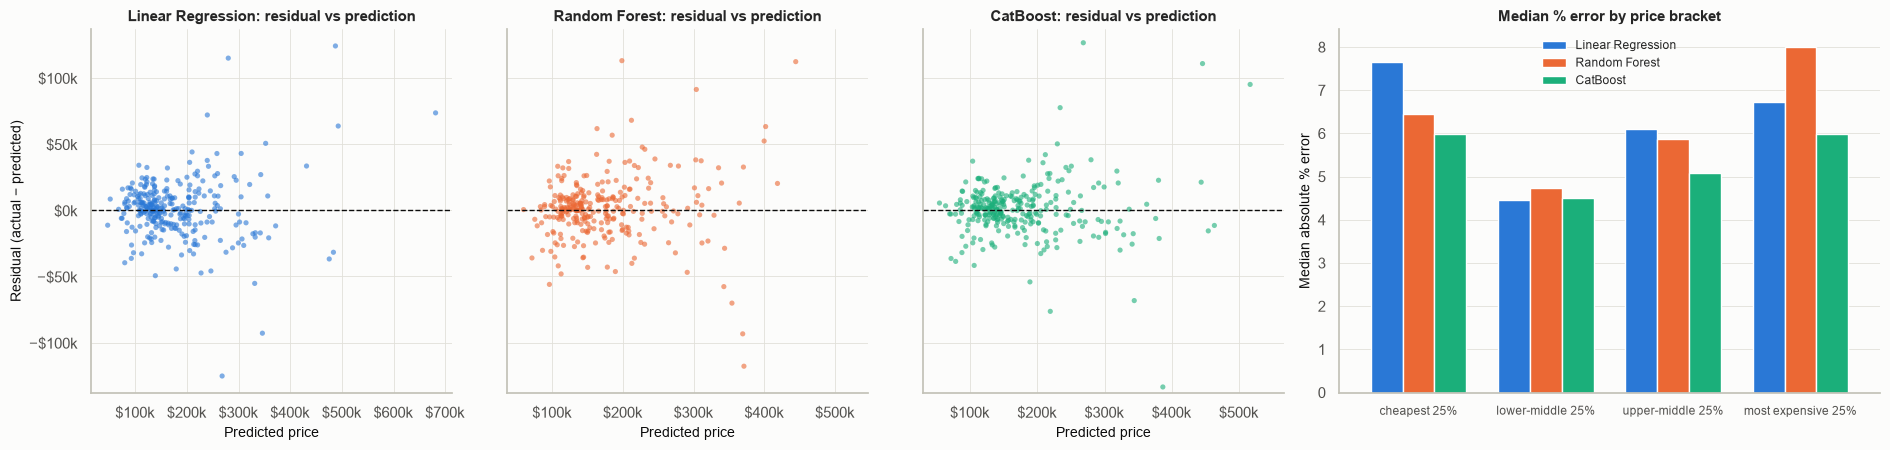

,Linear Regression,Random Forest,CatBoost
SalePrice,,,
cheapest 25%,7.7,6.5,6.0
lower-middle 25%,4.5,4.7,4.5
upper-middle 25%,6.1,5.9,5.1
most expensive 25%,6.7,8.0,6.0


In [40]:
# Percentage error by price bracket for every model
brackets = pd.qcut(y_val, q=4, labels=["cheapest 25%", "lower-middle 25%", "upper-middle 25%", "most expensive 25%"])
pct_error = pd.DataFrame({name: np.abs(pred - y_val.values) / y_val.values * 100
                          for name, pred in val_predictions.items()}, index=y_val.index)
by_bracket = pct_error.groupby(brackets, observed=True).median()

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
for ax, (name, pred) in zip(axes[:3], val_predictions.items()):
    ax.scatter(pred, y_val.values - pred, s=14, alpha=0.6, color=MODEL_COLORS[name], edgecolor="none")
    ax.axhline(0, color=INK, linestyle="--", linewidth=1)
    ax.set(title=f"{name}: residual vs prediction", xlabel="Predicted price")
    ax.xaxis.set_major_formatter(dollars)
    ax.yaxis.set_major_formatter(dollars)
axes[0].set_ylabel("Residual (actual − predicted)")
for ax in axes[1:3]:
    ax.sharey(axes[0])

by_bracket.plot.bar(ax=axes[3], color=[MODEL_COLORS[c] for c in by_bracket.columns], width=0.75, rot=0)
axes[3].set(title="Median % error by price bracket", xlabel="", ylabel="Median absolute % error")
axes[3].tick_params(axis="x", labelsize=8.5)
axes[3].grid(axis="x", visible=False)
axes[3].legend(frameon=False, fontsize=8.5)
fig.tight_layout()
plt.show()
by_bracket.round(1)

**What we learn from the residual analysis**
* **One house can move RMSE a lot.** Removing house 692 alone lowers CatBoost's validation RMSE from about \$25k to
  about \$21.7k, below Linear Regression's. RMSE squares errors, so a single \$200k miss dominates it. That's why we
  always look at MAE as well.
* **The hardest houses are mostly *Partial* sales**: brand-new homes sold before completion. Their prices include
  buyer-specific upgrades and negotiations that the 79 characteristics cannot capture.
* **No systematic pattern** remains in the residual-vs-prediction plots: errors scatter randomly around zero. Their
  spread grows with price, which is natural: a 6% error on a \$400k house is more dollars than on a \$100k house.
* **By median percentage error, CatBoost is the best or tied-best model in every price bracket**, including the most
  expensive quarter. Linear Regression's RMSE advantage comes from a handful of extreme houses, not from the
  expensive segment in general.

### 7.5 Which model is best so far?
No single model wins every metric, so we take a closer look at the two strongest ones. Both were scored on
**the same 5 folds**, so we can compare them fold by fold (a *paired* comparison):

In [41]:
paired = pd.DataFrame({
    "Linear Regression RMSE": fold_rmse["Linear Regression"],
    "CatBoost RMSE": fold_rmse["CatBoost"],
    "Linear Regression MAE": fold_mae["Linear Regression"],
    "CatBoost MAE": fold_mae["CatBoost"],
}, index=[f"Fold {k}" for k in range(1, cv.get_n_splits() + 1)])
paired.loc["Mean"] = paired.mean()

catboost_rmse_wins = int((fold_rmse["CatBoost"] < fold_rmse["Linear Regression"]).sum())
catboost_mae_wins = int((fold_mae["CatBoost"] < fold_mae["Linear Regression"]).sum())
print(f"CatBoost beats Linear Regression on RMSE in {catboost_rmse_wins} of 5 folds, on MAE in {catboost_mae_wins} of 5 folds.")
paired.style.format("${:,.0f}")

CatBoost beats Linear Regression on RMSE in 2 of 5 folds, on MAE in 3 of 5 folds.


,Linear Regression RMSE,CatBoost RMSE,Linear Regression MAE,CatBoost MAE
Fold 1,"$22,678","$21,757","$15,300","$13,808"
Fold 2,"$22,074","$22,992","$13,474","$13,747"
Fold 3,"$21,557","$26,335","$15,061","$13,795"
Fold 4,"$20,168","$18,848","$14,409","$12,442"
Fold 5,"$20,374","$23,283","$13,415","$13,757"
Mean,"$21,370","$22,643","$14,332","$13,510"


**Interpretation**
* **Random Forest** is the weakest model on every metric. Averaging deep trees on one-hot-encoded data is a solid
  default, but it does not beat the other two here.
* **Linear Regression vs. CatBoost is close, and the winner depends on the metric:**
  * Linear Regression has the lower **RMSE**, the metric that punishes *large* misses. Its advantage comes from the
    most expensive houses: a straight line can *extrapolate* above the highest training price, while tree models
    cannot predict beyond the prices they have seen (house 692 in 7.4 is the extreme example).
  * CatBoost has the lower **MAE**: for the *typical* house it is more accurate.
  * The RMSE gap is smaller than the variation between folds, so RMSE alone cannot separate the two reliably.
* Linear Regression has **no hyperparameters** to tune: least squares has one exact solution. CatBoost has many,
  and so far we have only used sensible defaults. So the next step is to **tune CatBoost**, then make the final decision.

---
## 8. Hyperparameter Tuning

**Parameters** are learned from the data (for example, the split points inside each tree).
**Hyperparameters** are settings we choose *before* training. Their best values depend on the dataset, so we search for them.

| Hyperparameter | What it controls | Too small | Too large |
|---|---|---|---|
| `depth` | how many questions each tree asks | trees too simple (underfitting) | trees memorise noise (overfitting), slower |
| `learning_rate` | how strongly each new tree corrects the previous ones | needs very many trees | unstable, overfits |
| `iterations` | number of trees | underfits | overfits, slower |
| `l2_leaf_reg` | penalty that keeps leaf values small (regularisation) | overfits | underfits |
| `random_strength` | randomness added when scoring splits | — | more randomness = more regularisation |
| `rsm` | share of features considered for each split | strong regularisation | 1.0 = all features |

**Grid search** would try every combination: 3 × 4 × 3 × 4 × 3 × 3 = 1,296 combinations × 5 folds, far too slow.
**Randomized search** tries a fixed number of random combinations and usually finds a good one at a fraction of the
cost. We try **15 combinations**, each scored on **the same 5 folds** as in Section 6.3 (75 model fits). On a mid-range
laptop the search took 4–7 minutes (the exact time is printed below). Colab's 2 free CPU cores may need longer; lower
`N_SEARCH_ITER` to save time.

Two rules keep the tuning honest:
1. The search only sees the **training set**. The validation set stays untouched.
2. Each candidate is refit inside every fold, so nothing leaks inside the search either.

In [42]:
param_distributions = {
    "regressor__depth": [4, 5, 6],
    "regressor__learning_rate": [0.02, 0.03, 0.05, 0.08],
    "regressor__iterations": [600, 1000, 1500],
    "regressor__l2_leaf_reg": [1, 3, 5, 10],
    "regressor__random_strength": [0.5, 1, 2],
    "regressor__rsm": [0.5, 0.8, 1.0],
}
N_SEARCH_ITER = 15     # lower it (e.g. to 8) for a faster, less thorough search

search = RandomizedSearchCV(
    estimator=log_target(CatBoostRegressor(**CATBOOST_PARAMS)),
    param_distributions=param_distributions,
    n_iter=N_SEARCH_ITER,
    cv=cv,                 # the same 5 folds as the model comparison
    scoring=scoring,       # record RMSE, MAE and R² for every candidate
    refit="RMSE",          # choose the lowest CV RMSE, then refit that candidate on the whole training set
    random_state=RANDOM_STATE,
    n_jobs=1,              # CatBoost already uses all CPU cores by itself
)

start = time.perf_counter()
search.fit(X_train_prepared, y_train)
print(f"Randomized search: {N_SEARCH_ITER} candidates × 5 folds finished in {(time.perf_counter() - start) / 60:.1f} minutes")

Randomized search: 15 candidates × 5 folds finished in 5.1 minutes


In [43]:
search_results = pd.DataFrame(search.cv_results_)
param_cols = [c for c in search_results.columns if c.startswith("param_")]
search_table = search_results[param_cols].rename(columns=lambda c: c.replace("param_regressor__", ""))
search_table["CV RMSE"] = -search_results["mean_test_RMSE"]
search_table["CV MAE"] = -search_results["mean_test_MAE"]
search_table["fit time (s)"] = search_results["mean_fit_time"]
search_table = search_table.sort_values("CV RMSE")

best_params = {name.replace("regressor__", ""): value for name, value in search.best_params_.items()}
print("Best hyperparameters found:", best_params)
print("Top 5 of the", N_SEARCH_ITER, "candidates:")
search_table.head(5).style.format({"CV RMSE": "${:,.0f}", "CV MAE": "${:,.0f}", "fit time (s)": "{:.1f}"})

Best hyperparameters found: {'rsm': 0.8, 'random_strength': 2, 'learning_rate': 0.05, 'l2_leaf_reg': 1, 'iterations': 1500, 'depth': 5}
Top 5 of the 15 candidates:


,rsm,random_strength,learning_rate,l2_leaf_reg,iterations,depth,CV RMSE,CV MAE,fit time (s)
2,0.800000,2.000000,0.050000,1,1500,5,"$21,890","$13,291",5.5
10,0.800000,2.000000,0.030000,1,1500,5,"$22,314","$13,380",5.5
4,0.500000,2.000000,0.020000,1,1500,6,"$22,408","$13,363",7.3
7,0.800000,2.000000,0.030000,3,1000,5,"$22,475","$13,410",3.8
12,0.800000,1.000000,0.020000,1,1500,5,"$22,510","$13,449",5.5


### 8.1 Did tuning help? Final comparison
We compare the tuned CatBoost with its default version and with Linear Regression, using the same 5 CV folds and the
**untouched validation set**, which is used here for the first time for the tuned model.

In [44]:
best_index = search.best_index_
tuned_fold_rmse = np.array([-search.cv_results_[f"split{k}_test_RMSE"][best_index] for k in range(cv.get_n_splits())])
tuned_fold_mae = np.array([-search.cv_results_[f"split{k}_test_MAE"][best_index] for k in range(cv.get_n_splits())])

tuned_catboost = search.best_estimator_            # already refit on the full training set
tuned_val_pred = tuned_catboost.predict(X_val_prepared)

candidates = {
    "Linear Regression": (fold_rmse["Linear Regression"], fold_mae["Linear Regression"], val_predictions["Linear Regression"]),
    "CatBoost (default)": (fold_rmse["CatBoost"], fold_mae["CatBoost"], val_predictions["CatBoost"]),
    "CatBoost (tuned)": (tuned_fold_rmse, tuned_fold_mae, tuned_val_pred),
}
final_rows = {}
for name, (f_rmse, f_mae, pred) in candidates.items():
    val_metrics = regression_metrics(y_val, pred)
    final_rows[name] = {"CV RMSE": f_rmse.mean(), "CV MAE": f_mae.mean(),
                        **{f"Val {metric}": value for metric, value in val_metrics.items()}}
final_comparison = pd.DataFrame(final_rows).T

money = ["CV RMSE", "CV MAE", "Val MAE", "Val RMSE"]
(final_comparison.style
    .format({**{c: "${:,.0f}" for c in money}, "Val R²": "{:.4f}", "Val RMSLE": "{:.4f}", "Val Within 10%": "{:.1%}"})
    .highlight_min(subset=money + ["Val RMSLE"], props="font-weight:bold")
    .highlight_max(subset=["Val R²", "Val Within 10%"], props="font-weight:bold"))

,CV RMSE,CV MAE,Val MAE,Val RMSE,Val R²,Val RMSLE,Val Within 10%
Linear Regression,"$21,370","$14,332","$14,970","$22,778",0.9324,0.1254,70.2%
CatBoost (default),"$22,643","$13,510","$14,213","$24,967",0.9187,0.1243,76.7%
CatBoost (tuned),"$21,890","$13,291","$14,246","$24,615",0.9210,0.1283,76.7%


In [45]:
paired_final = pd.DataFrame({
    "Linear Regression RMSE": fold_rmse["Linear Regression"], "Tuned CatBoost RMSE": tuned_fold_rmse,
    "Linear Regression MAE": fold_mae["Linear Regression"], "Tuned CatBoost MAE": tuned_fold_mae,
}, index=[f"Fold {k}" for k in range(1, cv.get_n_splits() + 1)])
paired_final.loc["Mean"] = paired_final.mean()
print(f"Tuned CatBoost beats Linear Regression on RMSE in {int((tuned_fold_rmse < fold_rmse['Linear Regression']).sum())} of 5 folds, "
      f"on MAE in {int((tuned_fold_mae < fold_mae['Linear Regression']).sum())} of 5 folds.")

# The single most expensive validation house again: how much of the RMSE gap does it explain?
keep = y_val.index != y_val.idxmax()
for name, pred in [("Linear Regression", val_predictions["Linear Regression"]), ("Tuned CatBoost", tuned_val_pred)]:
    print(f"{name:<18} validation RMSE without house {y_val.idxmax()}: ${np.sqrt(mean_squared_error(y_val[keep], pred[keep])):,.0f}")
paired_final.style.format("${:,.0f}")

Tuned CatBoost beats Linear Regression on RMSE in 2 of 5 folds, on MAE in 4 of 5 folds.
Linear Regression  validation RMSE without house 692: $22,406
Tuned CatBoost     validation RMSE without house 692: $22,272


,Linear Regression RMSE,Tuned CatBoost RMSE,Linear Regression MAE,Tuned CatBoost MAE
Fold 1,"$22,678","$21,373","$15,300","$13,438"
Fold 2,"$22,074","$22,613","$13,474","$13,627"
Fold 3,"$21,557","$24,708","$15,061","$13,689"
Fold 4,"$20,168","$18,592","$14,409","$12,518"
Fold 5,"$20,374","$22,164","$13,415","$13,184"
Mean,"$21,370","$21,890","$14,332","$13,291"


**Honest observations about tuning**
* In cross-validation, tuning improved CatBoost: CV RMSE fell from about \$22.6k to \$21.9k and CV MAE from \$13.5k to
  \$13.3k. But `search.best_score_` is slightly **optimistic**: we picked the best of 15 candidates *on these same
  folds*, so part of the gain is luck.
* On the **untouched validation set** the tuned and default CatBoost perform practically the same (MAE ≈ \$14.2k for
  both, RMSE slightly better, RMSLE slightly worse). So the gain from tuning is **within the noise** of a 292-house
  sample. That is a realistic outcome: CatBoost's defaults are already good, and good data preparation
  (Sections 4–5) matters at least as much as tuning.

### 8.2 Final model choice
The comparison is genuinely close, so here is the full reasoning:

| | Linear Regression | Tuned CatBoost |
|---|---|---|
| CV RMSE (5 folds) | **\$21,370** | \$21,890 (wins 2 of 5 folds) |
| CV MAE (5 folds) | \$14,332 | **\$13,291** (wins 4 of 5 folds) |
| Validation MAE | \$14,970 | **\$14,246** |
| Validation RMSE | **\$22,778** | \$24,615 |
| Validation R² | **0.932** | 0.921 |
| Validation: within ±10% of the true price | 70.2% | **76.7%** |

**Decision: the tuned CatBoost model**, because:
1. **It is more accurate for the typical house.** It has the lower MAE in cross-validation (4 of 5 folds) and on the validation
   set, and it prices 76.7% of unseen houses within ±10%, against 70.2% for Linear Regression.
2. **Linear Regression's RMSE advantage is fragile.** It comes from a handful of extreme houses (Section 7.4 and the
   check above). On RMSE the two models trade wins fold by fold.
3. **Its pipeline is simpler and more robust.** No log transforms, scaling or one-hot encoding are needed; missing values
   and unseen categories are handled natively; non-linear effects are learned automatically.

**The trade-off we accept:** CatBoost cannot predict above the most expensive houses in its training data, so it
under-prices rare luxury homes. If those mattered most (for example, a luxury-property agency), Linear Regression or a
blend of both models (see *Future improvements*) would be the better choice. **Choosing a model is a business decision
informed by metrics, not just the smallest number in one column.**

In [46]:
FINAL_MODEL_NAME = "CatBoost (tuned)"
print(f"Final model: {FINAL_MODEL_NAME}")
print("Hyperparameters:", best_params)

Final model: CatBoost (tuned)
Hyperparameters: {'rsm': 0.8, 'random_strength': 2, 'learning_rate': 0.05, 'l2_leaf_reg': 1, 'iterations': 1500, 'depth': 5}


---
## 9. Feature Importance and SHAP

People act on a price estimate only when they understand *why* the model produced it. We look at the tuned
CatBoost model in two ways:

1. **Global feature importance**: which features does the model rely on overall?
2. **SHAP values**: how much did each feature push *one particular* prediction up or down?

### 9.1 CatBoost's built-in feature importance
CatBoost measures how much the predictions change, on average, when a feature's value changes. The scores add up to 100.

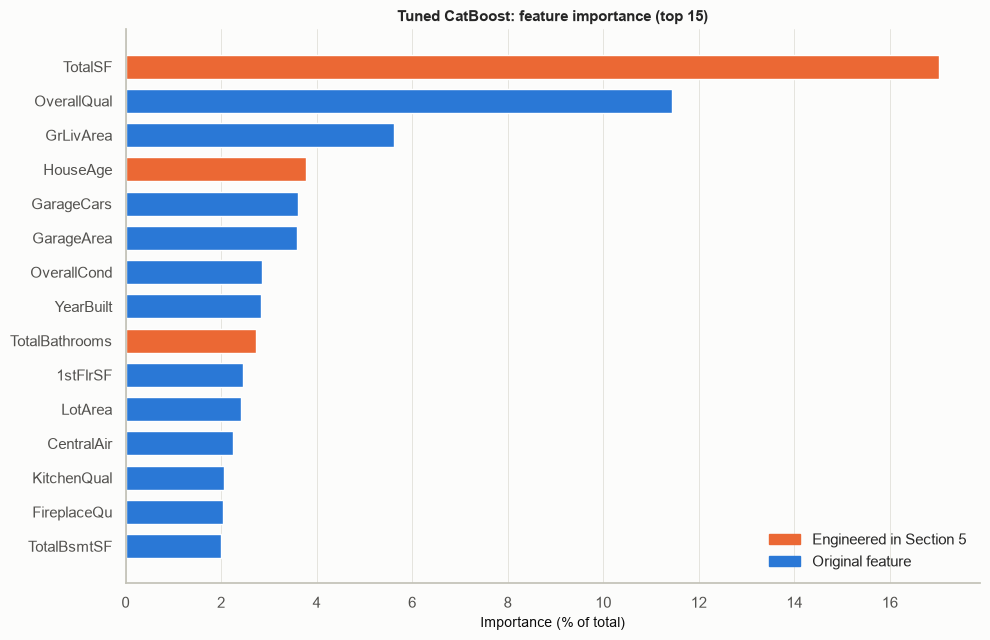

The 5 engineered features account for 26.1% of total importance.


In [47]:
best_catboost = tuned_catboost.regressor_            # the fitted CatBoostRegressor inside the log-target wrapper
ENGINEERED = {"TotalSF", "HouseAge", "YearsSinceRemodel", "TotalBathrooms", "TotalPorchSF"}

importance = pd.Series(best_catboost.get_feature_importance(), index=best_catboost.feature_names_).sort_values(ascending=False)
top_importance = importance.head(15)[::-1]

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(top_importance.index, top_importance.values, height=0.7,
        color=[ORANGE if f in ENGINEERED else BLUE for f in top_importance.index])
ax.set(title="Tuned CatBoost: feature importance (top 15)", xlabel="Importance (% of total)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=ORANGE, label="Engineered in Section 5"), Patch(color=BLUE, label="Original feature")],
          frameon=False, loc="lower right")
fig.tight_layout()
plt.show()
print(f"The 5 engineered features account for {importance[list(ENGINEERED)].sum():.1f}% of total importance.")

### 9.2 SHAP: explaining individual predictions
**SHAP** (SHapley Additive exPlanations) comes from cooperative game theory. For every single prediction it divides the
difference between *this house's prediction* and *the average prediction* fairly among the features:

$$\text{prediction} = \text{average prediction} + \text{SHAP}_{\text{OverallQual}} + \text{SHAP}_{\text{TotalSF}} + \text{SHAP}_{\text{Neighborhood}} + \dots$$

* A **positive** SHAP value pushed the price **up**; a **negative** value pushed it **down**.
* Our model predicts **log(price)**, so SHAP values are in log units. A value of **+0.10** means about **+10.5%**
  on the price ($e^{0.10}-1$). For small values, SHAP ≈ percentage effect.

`shap.TreeExplainer` computes exact SHAP values for tree models in seconds. We explain the 292 **validation** houses,
which the model has never seen.

In [48]:
explainer = shap.TreeExplainer(best_catboost)
shap_values = explainer(X_val_prepared)              # one SHAP value per house and feature
base_value = float(np.atleast_1d(shap_values.base_values)[0])

print("SHAP matrix shape:", shap_values.values.shape, "(houses × features)")
print(f"Average prediction (base value): {base_value:.3f} log units ≈ ${np.expm1(base_value):,.0f}")

# Sanity check: base value + sum of a house's SHAP values = the model's prediction for that house
reconstructed = shap_values.base_values + shap_values.values.sum(axis=1)
print("SHAP values add up exactly to the predictions:", np.allclose(reconstructed, best_catboost.predict(X_val_prepared)))

SHAP matrix shape: (292, 84) (houses × features)
Average prediction (base value): 12.031 log units ≈ $167,815
SHAP values add up exactly to the predictions: True


### 9.3 SHAP summary plot
How to read it:
* each **row** is a feature, sorted by overall impact (most important at the top);
* each **dot** is one validation house;
* the **horizontal position** is the SHAP value: right = pushed the price up, left = pushed it down;
* the **colour** is the feature's value for that house: red = high, blue = low. Text categories such as
  `FireplaceQu` have no high/low, so they are drawn in grey;
* the last row adds up **all remaining features**. Each one is small, but together they still matter.

Saved figure -> images/shap_summary.png


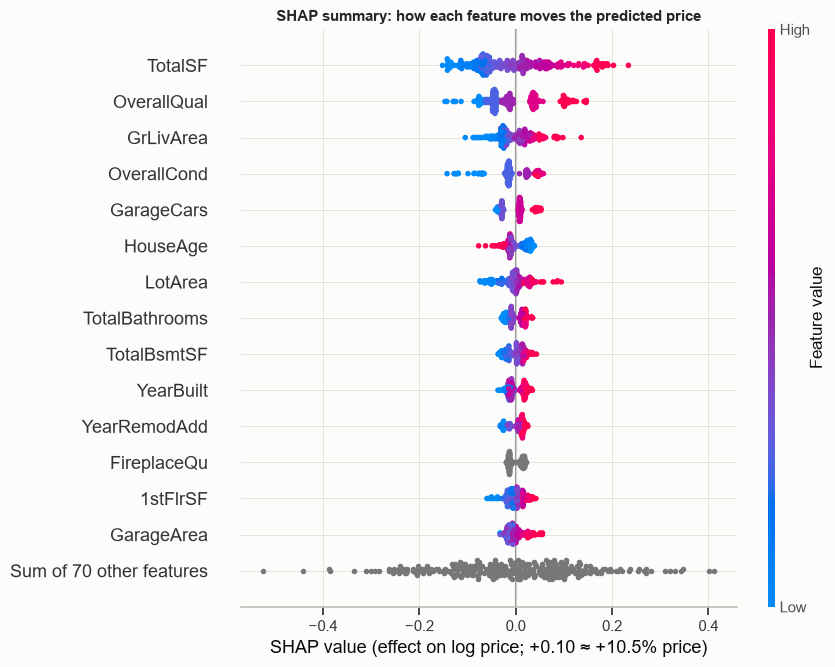

In [49]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
fig = plt.gcf()
fig.axes[0].set_title("SHAP summary: how each feature moves the predicted price", fontweight="bold")
fig.axes[0].set_xlabel("SHAP value (effect on log price; +0.10 ≈ +10.5% price)")
save_figure(fig, "shap_summary.png")
plt.show()

In [50]:
# Average size of each feature's effect, translated into an approximate percentage of the price
mean_abs_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_val_prepared.columns).sort_values(ascending=False)
top_shap = mean_abs_shap.head(10)
pd.DataFrame({
    "mean |SHAP| (log units)": top_shap.round(4),
    "typical effect on price": ((np.exp(top_shap) - 1) * 100).map("±{:.1f}%".format),
    "engineered?": ["yes" if f in ENGINEERED else "" for f in top_shap.index],
})

,mean |SHAP| (log units),typical effect on price,engineered?
TotalSF,0.0700,±7.3%,yes
OverallQual,0.0524,±5.4%,
GrLivArea,0.0294,±3.0%,
OverallCond,0.0284,±2.9%,
GarageCars,0.0215,±2.2%,
HouseAge,0.0187,±1.9%,yes
LotArea,0.0184,±1.9%,
TotalBathrooms,0.0156,±1.6%,yes
TotalBsmtSF,0.0155,±1.6%,
YearBuilt,0.0155,±1.6%,


### 9.4 Explaining one house
A **waterfall plot** explains a single prediction. It starts at the average prediction (bottom) and adds each
feature's SHAP value until it reaches this house's prediction (top). We pick a house from the middle of the price range.

House 911: actual price $154,300  |  predicted $151,543


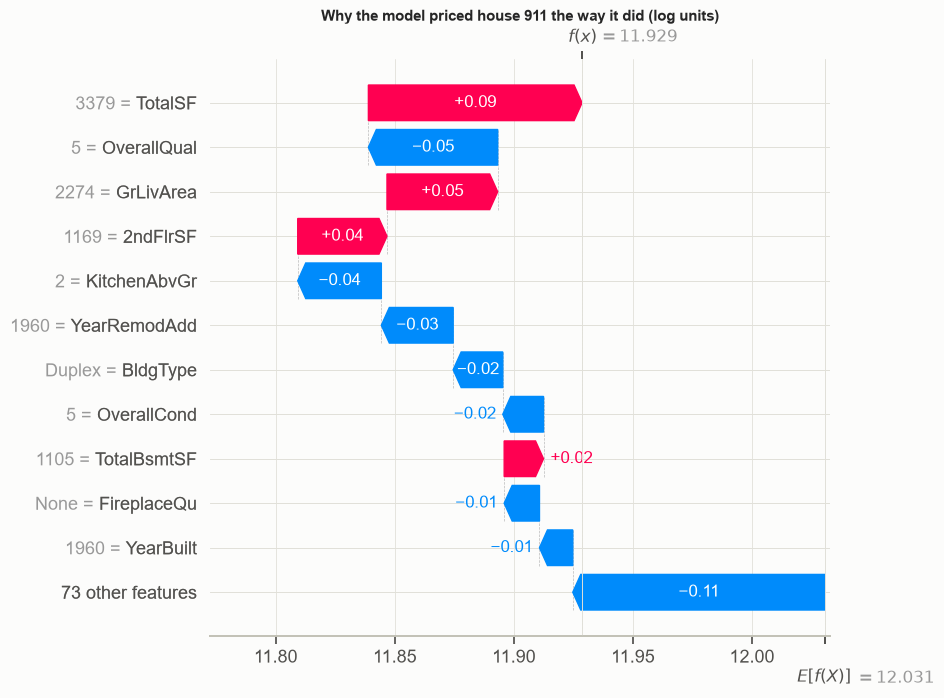

In [51]:
house_position = int(np.argsort(y_val.values)[len(y_val) // 2])       # median-priced validation house
house_id = y_val.index[house_position]
print(f"House {house_id}: actual price ${y_val.iloc[house_position]:,.0f}  |  predicted ${tuned_val_pred[house_position]:,.0f}")

shap.plots.waterfall(shap_values[house_position], max_display=12, show=False)
plt.gcf().axes[0].set_title(f"Why the model priced house {house_id} the way it did (log units)", fontweight="bold")
plt.show()

**Reading the waterfall.** House 911 is a two-storey **duplex** near the median price. The model starts from the average
prediction, 12.031 log units (≈ \$168k):
* its large total area (`TotalSF` +0.09), living area (`GrLivArea` +0.05) and second floor (+0.04) push the price **up**;
* its average quality (`OverallQual` = 5, −0.05), its second kitchen (`KitchenAbvGr` = 2, typical of duplexes, −0.04)
  and a last remodel in 1960 (−0.03) push it **down**;
* 73 smaller effects add up to −0.11.

The result, 11.929 log units ≈ **\$151.5k**, is close to the actual sale price of \$154.3k. Every prediction can be
explained this way, which is valuable when a buyer or a bank asks *"why this price?"*.

### 9.5 How an effect changes with the feature's value
A SHAP **dependence plot** shows a feature's value (x-axis) against its SHAP value (y-axis) for every house. It reveals
the *shape* of the effect, which a single importance number cannot.

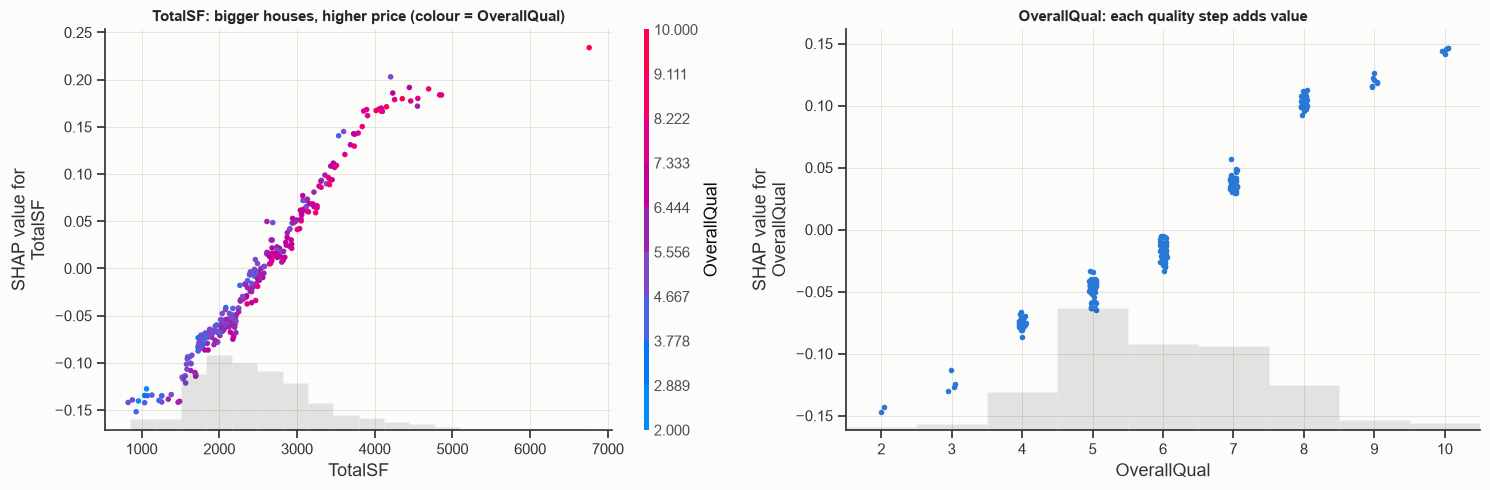

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
shap.plots.scatter(shap_values[:, "TotalSF"], color=shap_values[:, "OverallQual"], ax=axes[0], show=False)
axes[0].set_title("TotalSF: bigger houses, higher price (colour = OverallQual)", fontweight="bold")
shap.plots.scatter(shap_values[:, "OverallQual"], color=BLUE, ax=axes[1], show=False)
axes[1].set_title("OverallQual: each quality step adds value", fontweight="bold")
fig.tight_layout()
plt.show()

**What we see**
* **Left:** the effect of `TotalSF` rises steadily from about 1,500 to 4,000 sq ft (from about −0.13 to +0.17, a price
  difference of roughly 35%) and then **flattens**: there are too few bigger houses to learn from. The colours also
  show that bigger houses tend to have higher quality.
* **Right:** each `OverallQual` step adds roughly +0.02 to +0.07 log units (≈ 2–7%). Going from quality 5 to 8 adds
  about +0.15, i.e. **≈ +16%** on the price, *on top of* the effects of size, age, etc.

### 9.6 What drives house prices? (plain language)
1. **Size is king.** Total square footage (`TotalSF`) is the most influential feature. On average it moves a prediction
   by about ±7%, and for the biggest houses by +20% or more.
2. **Quality comes next.** The overall quality rating (≈ ±5% on average) and the overall condition rating (≈ ±3%).
3. **Age and garage matter.** Newer houses (`HouseAge`) and garages for more cars (`GarageCars`) add value.
4. **Feature engineering paid off.** `TotalSF`, `HouseAge` and `TotalBathrooms` are among the top 8 SHAP features, and the
   five engineered features account for about a quarter of CatBoost's total importance.
5. **Location works mostly indirectly.** Neighbourhood median prices differ 2.5–3.5× (Section 3.3), but most of that gap
   is explained by *which* houses stand there: their size, quality and age. Moving the *same* house to another
   neighbourhood changes its predicted price by only about −4% to +5% (Section 10.4).
6. **SHAP explains the model, not the world.** A positive SHAP value for a fireplace does not prove that *adding* a
   fireplace raises the price by that amount. It describes patterns in past sales, not cause and effect.

---
## 10. Final Prediction

### 10.1 Retrain on all labelled data and save the model
During development we held back 292 houses to measure the models honestly. Now that every decision is made, we
retrain the chosen model, with the tuned hyperparameters, on **all labelled houses** (the two documented outliers are
still excluded). More data gives a slightly better model.

Its expected accuracy is the **validation result from Section 8**. The final model can no longer be evaluated on
houses it was trained on, which is exactly why the validation set was kept separate until the end.

In [53]:
final_outliers = (X["GrLivArea"] > 4000) & (y < 300_000)
X_full = prepare_features(X.loc[~final_outliers])
y_full = y.loc[~final_outliers]

final_model = clone(tuned_catboost)                  # same pipeline and tuned hyperparameters, not yet trained
start = time.perf_counter()
final_model.fit(X_full, y_full)
print(f"Final model trained on {len(X_full):,} houses in {time.perf_counter() - start:.1f}s")

Final model trained on 1,458 houses in 6.1s


In [54]:
MODEL_PATH = MODELS_DIR / "best_model.cbm"
final_model.regressor_.save_model(str(MODEL_PATH))   # CatBoost's own compact binary format
print(f"Saved -> models/{MODEL_PATH.name}  ({MODEL_PATH.stat().st_size / 1024:,.0f} KB)")

# Load it back, exactly as an application would, and check it reproduces the same predictions
loaded_model = CatBoostRegressor()
loaded_model.load_model(str(MODEL_PATH))
check_rows = X_full.head(100)
identical = np.allclose(loaded_model.predict(check_rows), final_model.regressor_.predict(check_rows))
print("Reloaded model reproduces the predictions:", identical)

Saved -> models/best_model.cbm  (881 KB)
Reloaded model reproduces the predictions: True


The `.cbm` file stores the CatBoost model, which predicts **log(1 + price)**. To use it we must (1) prepare the input
exactly as in training, using `prepare_features()`, and (2) convert the output back to dollars with `np.expm1`.
The prediction function below does both.

### 10.2 The prediction function
`predict_house_price(input_data)` accepts:
* a **dict** describing one house → returns one price (a `float`);
* a **list of dicts** or a **DataFrame** (e.g. rows of Kaggle's `test.csv`) → returns an array of prices.

You only need to give the characteristics you know. Everything else is filled with the value of a **typical Ames
house** (median for numbers, most common value for categories), computed from the labelled data.
Misspelled column names raise a clear error instead of being silently ignored.

In [55]:
FEATURE_COLUMNS = X.columns.tolist()                       # the 79 raw characteristics
reference = clean_data(X.loc[~final_outliers])             # cleaned, so "no pool" is "None" rather than missing
TYPICAL_HOUSE = {
    col: float(reference[col].median()) if pd.api.types.is_numeric_dtype(reference[col]) else reference[col].mode().iloc[0]
    for col in FEATURE_COLUMNS
}
print("A few typical values:", {k: TYPICAL_HOUSE[k] for k in ["Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "GarageCars", "PoolQC"]})


def predict_house_price(input_data, model=loaded_model):
    """Predict the sale price (USD) of one or more houses.

    input_data: dict (one house), list of dicts, or DataFrame using the Kaggle column names.
                Missing characteristics are filled with typical values.
    Returns a float for a single dict, otherwise a NumPy array of prices.
    """
    single_house = isinstance(input_data, dict)
    houses = pd.DataFrame([input_data]) if single_house else pd.DataFrame(input_data).copy()
    houses = houses.drop(columns=["Id", TARGET], errors="ignore")      # allowed in the input, but not used

    unknown = sorted(set(houses.columns) - set(FEATURE_COLUMNS))
    if unknown:
        raise ValueError(f"Unknown characteristics {unknown}. Column names are case-sensitive, e.g. 'GrLivArea'.")

    # Sensible defaults: a house that was never remodelled has YearRemodAdd = YearBuilt (same for the garage)
    for col in ["YearRemodAdd", "GarageYrBlt"]:
        if col not in houses.columns and "YearBuilt" in houses.columns:
            houses[col] = houses["YearBuilt"]
    for col in FEATURE_COLUMNS:
        if col not in houses.columns:
            houses[col] = TYPICAL_HOUSE[col]

    features = prepare_features(houses[FEATURE_COLUMNS])            # identical preparation as in training
    log_prices = model.predict(features[model.feature_names_])      # the model predicts log(1 + price)
    prices = np.expm1(log_prices)
    return float(prices[0]) if single_house else prices

A few typical values: {'Neighborhood': 'NAmes', 'OverallQual': 6.0, 'GrLivArea': 1461.5, 'YearBuilt': 1972.5, 'GarageCars': 2.0, 'PoolQC': 'None'}


### 10.3 Demonstration on sample properties
Three hand-made houses that are not in the dataset. All values are typical of Ames homes.

In [56]:
sample_houses = {
    "Small older starter home": {
        "Neighborhood": "Edwards", "OverallQual": 5, "OverallCond": 6, "YearBuilt": 1955, "YearRemodAdd": 1995,
        "GrLivArea": 1050, "1stFlrSF": 1050, "2ndFlrSF": 0, "TotalBsmtSF": 900, "FullBath": 1, "HalfBath": 0,
        "BedroomAbvGr": 3, "KitchenQual": "TA", "GarageCars": 1, "GarageArea": 300, "LotArea": 8000,
    },
    "Modern family home": {
        "Neighborhood": "CollgCr", "OverallQual": 7, "YearBuilt": 2004, "GrLivArea": 1800, "1stFlrSF": 950,
        "2ndFlrSF": 850, "TotalBsmtSF": 950, "FullBath": 2, "HalfBath": 1, "BedroomAbvGr": 3, "KitchenQual": "Gd",
        "ExterQual": "Gd", "GarageCars": 2, "GarageArea": 520, "Fireplaces": 1, "LotArea": 9500,
    },
    "Large new luxury home": {
        "Neighborhood": "NridgHt", "OverallQual": 9, "YearBuilt": 2008, "GrLivArea": 2900, "1stFlrSF": 1900,
        "2ndFlrSF": 1000, "TotalBsmtSF": 1900, "BsmtQual": "Ex", "FullBath": 3, "HalfBath": 1, "BedroomAbvGr": 4,
        "KitchenQual": "Ex", "ExterQual": "Ex", "GarageCars": 3, "GarageArea": 850, "GarageFinish": "Fin",
        "Fireplaces": 2, "LotArea": 13000,
    },
}

demo = pd.DataFrame([
    {"House": label, "Neighborhood": h["Neighborhood"], "OverallQual": h["OverallQual"], "GrLivArea": h["GrLivArea"],
     "YearBuilt": h["YearBuilt"], "Predicted price": predict_house_price(h)}
    for label, h in sample_houses.items()
]).set_index("House")
demo.style.format({"Predicted price": "${:,.0f}", "GrLivArea": "{:,} sq ft"})

,Neighborhood,OverallQual,GrLivArea,YearBuilt,Predicted price
House,,,,,
Small older starter home,Edwards,5,"1,050 sq ft",1955,"$127,058"
Modern family home,CollgCr,7,"1,800 sq ft",2004,"$201,095"
Large new luxury home,NridgHt,9,"2,900 sq ft",2008,"$434,490"


### 10.4 What-if analysis
Because the function is cheap to call, we can ask *"what if…?"*: we change one characteristic of the modern family
home and keep everything else fixed.

In [57]:
family_home = sample_houses["Modern family home"]

quality_effect = pd.DataFrame(
    {"Predicted price": [predict_house_price({**family_home, "OverallQual": q}) for q in range(4, 11)]},
    index=pd.Index(range(4, 11), name="OverallQual"))
quality_effect["vs. actual quality (7)"] = quality_effect["Predicted price"] / quality_effect.loc[7, "Predicted price"] - 1

neighborhoods = ["MeadowV", "Edwards", "NAmes", "CollgCr", "Somerst", "NridgHt", "StoneBr"]
location_effect = pd.DataFrame(
    {"Predicted price": [predict_house_price({**family_home, "Neighborhood": n}) for n in neighborhoods]},
    index=pd.Index(neighborhoods, name="Neighborhood"))
location_effect["vs. actual location (CollgCr)"] = location_effect["Predicted price"] / location_effect.loc["CollgCr", "Predicted price"] - 1

display(quality_effect.style.format({"Predicted price": "${:,.0f}", "vs. actual quality (7)": "{:+.1%}"}))
display(location_effect.style.format({"Predicted price": "${:,.0f}", "vs. actual location (CollgCr)": "{:+.1%}"}))

,Predicted price,vs. actual quality (7)
OverallQual,,
4,"$179,093",-10.9%
5,"$185,871",-7.6%
6,"$189,447",-5.8%
7,"$201,095",+0.0%
8,"$208,168",+3.5%
9,"$214,779",+6.8%
10,"$215,808",+7.3%


,Predicted price,vs. actual location (CollgCr)
Neighborhood,,
MeadowV,"$192,602",-4.2%
Edwards,"$198,055",-1.5%
NAmes,"$199,751",-0.7%
CollgCr,"$201,095",+0.0%
Somerst,"$204,471",+1.7%
NridgHt,"$201,364",+0.1%
StoneBr,"$211,836",+5.3%


**Two lessons from the what-if analysis**
* **Changing one feature in isolation has a smaller effect than raw price differences suggest.** Raising only
  `OverallQual` from 7 to 10 adds about +7%, far less than the gap between typical quality-7 and quality-10 houses in
  Section 3.5. In reality a quality-10 house is also bigger, newer and has an excellent kitchen. Here we change *one*
  characteristic and keep everything else fixed.
* **Location has a modest direct effect in this model** (about −4% to +5%), for the same reason (see 9.6).

What-if questions are a powerful way to communicate a model to non-technical people. They show what the *model* has
learned from past sales, which is not necessarily cause and effect.

### 10.5 Batch input and input validation
The function also accepts complete records in the original Kaggle format, for example rows of `test.csv`. Below we pass
three raw rows from our data only to show the input format. The final model was trained on these houses, so this is
**not** an accuracy check.

In [58]:
raw_rows = X.head(3)
batch = pd.DataFrame({"Predicted price": predict_house_price(raw_rows), "Actual price": y.loc[raw_rows.index]})
display(batch.style.format("${:,.0f}"))

# A typo in a column name is reported instead of being silently ignored
try:
    predict_house_price({"GrLivarea": 1500})
except ValueError as error:
    print("ValueError:", error)

,Predicted price,Actual price
Id,,
1,"$205,595","$208,500"
2,"$180,764","$181,500"
3,"$215,882","$223,500"


ValueError: Unknown characteristics ['GrLivarea']. Column names are case-sensitive, e.g. 'GrLivArea'.


---
## 11. Conclusion

In [59]:
final_val_metrics = regression_metrics(y_val, tuned_val_pred)
print(f"Final model:      {FINAL_MODEL_NAME}")
print(f"Hyperparameters:  {best_params}")
print(f"5-fold CV:        RMSE ${tuned_fold_rmse.mean():,.0f}   MAE ${tuned_fold_mae.mean():,.0f}")
print("Validation set (292 unseen houses):")
print(f"   MAE   ${final_val_metrics['MAE']:,.0f}")
print(f"   RMSE  ${final_val_metrics['RMSE']:,.0f}")
print(f"   R²    {final_val_metrics['R²']:.4f}")
print(f"   RMSLE {final_val_metrics['RMSLE']:.4f}")
print(f"   {final_val_metrics['Within 10%']:.1%} of houses predicted within ±10% of the true price")
print("Most influential features (mean |SHAP|):", ", ".join(mean_abs_shap.head(6).index))
print(f"Saved model:      models/{MODEL_PATH.name}")

Final model:      CatBoost (tuned)
Hyperparameters:  {'rsm': 0.8, 'random_strength': 2, 'learning_rate': 0.05, 'l2_leaf_reg': 1, 'iterations': 1500, 'depth': 5}
5-fold CV:        RMSE $21,890   MAE $13,291
Validation set (292 unseen houses):
   MAE   $14,246
   RMSE  $24,615
   R²    0.9210
   RMSLE 0.1283
   76.7% of houses predicted within ±10% of the true price
Most influential features (mean |SHAP|): TotalSF, OverallQual, GrLivArea, OverallCond, GarageCars, HouseAge
Saved model:      models/best_model.cbm


### 11.1 Summary
**Goal:** predict the sale price of houses in Ames, Iowa from 79 characteristics, compare three algorithms fairly,
and explain the best one.

**Best-performing model: tuned CatBoost** (depth 5, learning rate 0.05, 1,500 trees, `l2_leaf_reg` 1,
`random_strength` 2, `rsm` 0.8), saved as `models/best_model.cbm`.

| Validation set (292 unseen houses) | Tuned CatBoost | Linear Regression (baseline) | Random Forest |
|---|---|---|---|
| MAE | **\$14,246** | \$14,970 | \$17,169 |
| RMSE | \$24,615 | **\$22,778** | \$29,089 |
| R² | 0.921 | **0.932** | 0.890 |
| RMSLE | 0.128 | 0.125 | 0.147 |
| Within ±10% of the true price | **76.7%** | 70.2% | 68.8% |

**In plain words:** on houses it has never seen, the model is off by about **\$14k on average** (under 10% of a typical
\$160k–\$180k price). It explains **92% of the variation** in prices, and **3 out of 4 estimates are within ±10%** of the
actual sale price.

**Model comparison:** CatBoost and a carefully prepared Linear Regression (log target, log-transformed areas, grouped
rare categories) were close, with different strengths: CatBoost is better for typical houses (MAE, ±10% hit rate), Linear
Regression for the rare extreme ones (RMSE). Random Forest was clearly the weakest. Tuning improved CatBoost in
cross-validation, but the gain was within noise on the validation set.

**Most influential features:** total square footage (`TotalSF`), overall quality, living area, overall condition,
garage size and house age. Three of the five engineered features rank among the top 8.

### 11.2 Limitations
* **Small, local, dated data.** 1,460 sales from one US city in 2006–2010 (including the 2008 financial crisis). The
  model will not transfer to other markets or to today's prices without retraining on new data.
* **Uncertainty in the metrics.** With 292 validation houses, metrics shift by hundreds to thousands of dollars
  depending on which houses happen to be in the sample (CV fold scores varied by roughly ±\$1–2.5k).
* **Trees cannot extrapolate.** CatBoost under-prices rare luxury homes above the training price range (e.g. house 692).
* **Unusual sale types.** *Partial* sales of new homes and *abnormal* sales (foreclosures, family sales) are hard to
  predict from house characteristics alone.
* **Small tuning budget.** Only 15 random hyperparameter combinations were tried.
* **Correlation, not causation.** Feature importance, SHAP and what-if results describe patterns the model learned, not
  the effect of renovating a house.

### 11.3 Future improvements
* **Blend Linear Regression and CatBoost.** Their errors differ (LR handles extremes, CatBoost typical houses), and
  averaging such models is a classic way to beat both.
* **Regularised linear models** (Ridge, Lasso, ElasticNet) instead of plain least squares.
* **Ordinal encoding** of the quality scales (Po < Fa < TA < Gd < Ex), so the linear model knows their order.
* **Richer features:** quality × size interactions, neighbourhood price levels (computed inside the CV folds to avoid leakage).
* **Smarter tuning:** Bayesian optimisation (e.g. Optuna) with early stopping, and repeated or nested cross-validation for
  more reliable model comparisons.
* **Prediction intervals:** quantile regression to output a price *range* (e.g. \$185k–\$215k) instead of a single number.
* **Deployment:** wrap `predict_house_price()` in a small web app (Streamlit or FastAPI) and monitor incoming data for drift.